#### **Libraries and modules**

In [18]:
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pathlib import Path
from datetime import datetime
from cmcrameri import cm as cmc

#### **Load AIFS-ENS and ERA5 data**

In [19]:
# Load AIFS dataset
AIFS_filename_sfc = "AIFS-ENS_02_Foehn_SouthAmerica_sfc_2025-11-17_18UTC.nc"
ds_AIFS_sfc = xr.open_dataset(AIFS_filename_sfc)

AIFS_filename_pl = "AIFS-ENS_02_Foehn_SouthAmerica_pl_2025-11-17_18UTC.nc"
ds_AIFS_pl = xr.open_dataset(AIFS_filename_pl)

# Load ERA5 dataset
ERA5_filename_sfc = "ERA5_02_Foehn_SouthAmerica_sfc_2025-11-17_18UTC.nc"
ds_ERA5_sfc = xr.open_dataset(ERA5_filename_sfc)

ERA5_filename_pl = "ERA5_02_Foehn_SouthAmerica_pl_2025-11-17_18UTC.nc"
ds_ERA5_pl = xr.open_dataset(ERA5_filename_pl)


#### **Create wind speed as a new variable in the xarray dataset**

In [20]:
# Surface wind speed AIFS
ds_AIFS_sfc["wind_speed"] = np.sqrt(ds_AIFS_sfc["u10"]**2 + ds_AIFS_sfc["v10"]**2)

# Wind speed at pressure levels AIFS
ds_AIFS_pl["wind_speed"] = np.sqrt(ds_AIFS_pl["u"]**2 + ds_AIFS_pl["v"]**2)

# Surface wind speed ERA5
ds_ERA5_sfc["wind_speed"] = np.sqrt(ds_ERA5_sfc["u10"]**2 + ds_ERA5_sfc["v10"]**2)

# Wind speed at pressure levels ERA5
ds_ERA5_pl["wind_speed"] = np.sqrt(ds_ERA5_pl["u"]**2 + ds_ERA5_pl["v"]**2)

#### **Select the target time (valid time of forecast)**

In [21]:
target_time = pd.to_datetime("2025-11-17_18UTC", format="%Y-%m-%d_%HUTC")

#### **Locate max. wind speeds in ERA5**

In [22]:
# Max. wind speed surface wind in ERA5
wind_speed_max_ERA5_sfc = float(ds_ERA5_sfc["wind_speed"].max())
max_flat_idx = int(np.nanargmax(ds_ERA5_sfc["wind_speed"].values))
max_idx = np.unravel_index(max_flat_idx, ds_ERA5_sfc["wind_speed"].shape)

lat_max_ERA5_sfc = float(ds_ERA5_sfc["wind_speed"].latitude.values[max_idx[0]])
lon_max_ERA5_sfc = float(ds_ERA5_sfc["wind_speed"].longitude.values[max_idx[1]])

print(f"ERA5 max. wind speed for surface wind: {wind_speed_max_ERA5_sfc:.2f} m s^-1")
print(f"Location (lat, lon): ({lat_max_ERA5_sfc:.2f}, {lon_max_ERA5_sfc:.2f})")

# Max. wind speed at 500 hPa in ERA5
wind_max_500hPa_ERA5_pl = ds_ERA5_pl["wind_speed"].sel(isobaricInhPa=500, method="nearest").squeeze()

wind_speed_max_500hPa_ERA5_pl = float(wind_max_500hPa_ERA5_pl.max())
max_flat_idx = int(np.nanargmax(wind_max_500hPa_ERA5_pl.values))
max_idx = np.unravel_index(max_flat_idx, wind_max_500hPa_ERA5_pl.shape)

lat_max_500hPa_ERA5_pl = float(wind_max_500hPa_ERA5_pl.latitude.values[max_idx[0]])
lon_max_500hPa_ERA5_pl = float(wind_max_500hPa_ERA5_pl.longitude.values[max_idx[1]])

print(f"ERA5 max. wind speed at 500 hPa: {wind_speed_max_500hPa_ERA5_pl:.2f} m s^-1")
print(f"Location (lat, lon): ({lat_max_500hPa_ERA5_pl:.2f}, {lon_max_500hPa_ERA5_pl:.2f})")

ERA5 max. wind speed for surface wind: 22.85 m s^-1
Location (lat, lon): (-50.75, -70.00)
ERA5 max. wind speed at 500 hPa: 65.50 m s^-1
Location (lat, lon): (-48.25, -72.00)


#### **Subset AIFS wind speed at the location of ERA5 max. wind speed**

In [23]:
# Convert longitude from ERA5 to AIFS convention (0 to 360)
lon_max_aifs_sfc = lon_max_ERA5_sfc % 360

# Find the closest forecast time in AIFS to the target time
target_time = np.datetime64("2025-11-17T18:00:00")
lead_idx = int(np.argmin(np.abs(ds_AIFS_sfc["fc_valid_time"].values - target_time)))
lead_sel = ds_AIFS_sfc["leadtime"].values[lead_idx]

# Extact the wind speed at the location of the maximum wind speed in ERA5 for the corresponding lead time in AIFS
aifs_wind_extreme_loc = ds_AIFS_sfc["wind_speed"].sel(
    latitude=lat_max_ERA5_sfc,
    longitude=lon_max_aifs_sfc,
    leadtime=lead_sel,
    method="nearest"
)

# Select the nearest AIFS grid point at the ERA5 max. wind speed location for the corresponding lead time
aifs_point = ds_AIFS_sfc.sel(
    latitude=lat_max_ERA5_sfc,
    longitude=lon_max_aifs_sfc,
    leadtime=lead_sel,
    method="nearest"
)

# Select the AIFS wind speed at the ERA5 max. wind location for the corresponding lead time
ds_AIFS_sfc_sel_wind_speed = ds_AIFS_sfc["wind_speed"].sel(
    latitude=lat_max_ERA5_sfc,
    longitude=lon_max_aifs_sfc,
    method="nearest"
)

## **Plotting**

#### **Set output directory for all plots**

In [24]:
# Default output directory for all plots
PLOT_DIR = Path(
    r"C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc"
    r"\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks"
    r"\01_Case_Study\01_Code\01_Plots\01_wind"
)

def save_plot(
    fig,
    plot_name,
    output_dir=PLOT_DIR,
    dpi=300
):
    """
    Save a Matplotlib figure as both PNG and PDF.

    PNG files are saved in:
        output_dir/png

    PDF files are saved in:
        output_dir/pdf

    Files are named:
        YYYYMMDD_wind_plot_name.png
        YYYYMMDD_wind_plot_name.pdf

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure that should be saved.
    plot_name : str
        Descriptive filename without the date or file extension.
    output_dir : str or pathlib.Path
        Main directory containing the PNG and PDF subfolders.
    dpi : int
        Resolution of the PNG file.
    """

    output_dir = Path(output_dir)

    # Separate output directories
    png_dir = output_dir / "01_png"
    pdf_dir = output_dir / "02_pdf"

    # Create directories if they do not already exist
    png_dir.mkdir(parents=True, exist_ok=True)
    pdf_dir.mkdir(parents=True, exist_ok=True)

    current_date = datetime.now().strftime("%Y%m%d")

    # Prevent unwanted spaces in filenames
    clean_plot_name = plot_name.strip().replace(" ", "_")

    filename = f"{current_date}_wind_{clean_plot_name}"

    png_path = png_dir / f"{filename}.png"
    pdf_path = pdf_dir / f"{filename}.pdf"

    # High-resolution raster image
    fig.savefig(
        png_path,
        dpi=dpi,
        bbox_inches="tight"
    )

    # Vector image
    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    print(
        "Plots saved as:\n"
        f"PNG: {png_path}\n"
        f"PDF: {pdf_path}"
    )

    return png_path, pdf_path

### **Boxplots**

#### **Boxplot comparing AIFS ensemble surface wind speeds with max. surface wind speed in ERA5**  

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_boxplot_sfc_AIFS_ERA5_max.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_boxplot_sfc_AIFS_ERA5_max.pdf


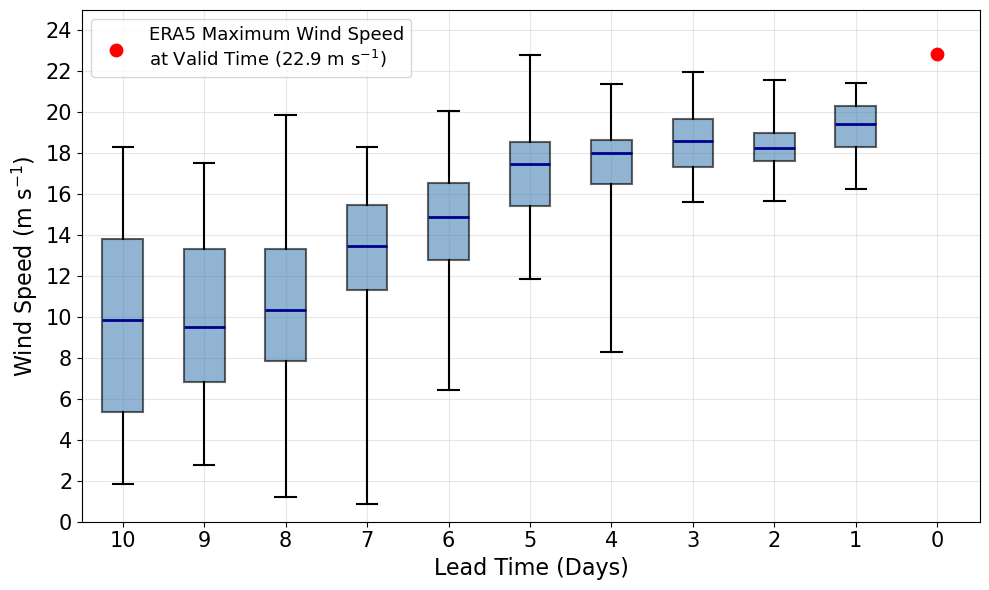

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))

leadtimes = np.arange(1, 10 + 1, 1)
n_leads = len(leadtimes)

# Reverse data so lead time 10 days appears first
data_reversed = ds_AIFS_sfc_sel_wind_speed.values[:, ::-1]

box = ax.boxplot(
    data_reversed,
    positions=np.arange(1, n_leads + 1),
    whis=[0, 100],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(
        facecolor="steelblue",
        alpha=0.6,
        linewidth=1.5
    ),
    medianprops=dict(
        color="darkblue",
        linewidth=2
    ),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5)
)

# ERA5 point: maximum surface wind speed
ax.scatter(
    n_leads + 1,
    wind_speed_max_ERA5_sfc,
    color="red",
    marker="o",
    s=80,
    zorder=5,
    label=(
        "ERA5 Maximum Wind Speed\n"
        f"at Valid Time ({wind_speed_max_ERA5_sfc:.1f} "
        "m s$^{-1}$)"
    )
)

# Tick labels
xtick_positions = np.arange(1, n_leads + 2)
xtick_labels = list(leadtimes[::-1]) + [0]

ax.set_xticks(xtick_positions)
ax.set_xticklabels(xtick_labels, fontsize=15)
ax.tick_params(axis="y", labelsize=15)

# Show y-axis labels from 0 to 24 m s^-1
ax.set_ylim(0, 25)
ax.set_yticks(np.arange(0, 24 + 2, 2))

valid_time = pd.to_datetime(
    ds_AIFS_sfc_sel_wind_speed["fc_valid_time"].values[0]
)
time_str = valid_time.strftime("%Y-%m-%d %H:%M")

ax.set_xlabel("Lead Time (Days)", fontsize=16)
ax.set_ylabel("Wind Speed (m s$^{-1}$)", fontsize=16)

ax.legend(fontsize=13, loc="upper left")
ax.set_axisbelow(True)
ax.grid(alpha=0.3)

fig.tight_layout()

png_path, pdf_path = save_plot(
    fig,
    "boxplot_sfc_AIFS_ERA5_max"
)

plt.show()
plt.close(fig)

#### **Boxplot comparing AIFS ensemble surface wind speeds with max. surface wind speed in ERA5 with spatial shift allowance - AIFS finds max. wind speeds within ±2.0° lat, ±2.0° lon of the ERA5 maximum location**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_boxplot_sfc_AIFS_ERA5_max_spatial_allowance.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_boxplot_sfc_AIFS_ERA5_max_spatial_allowance.pdf


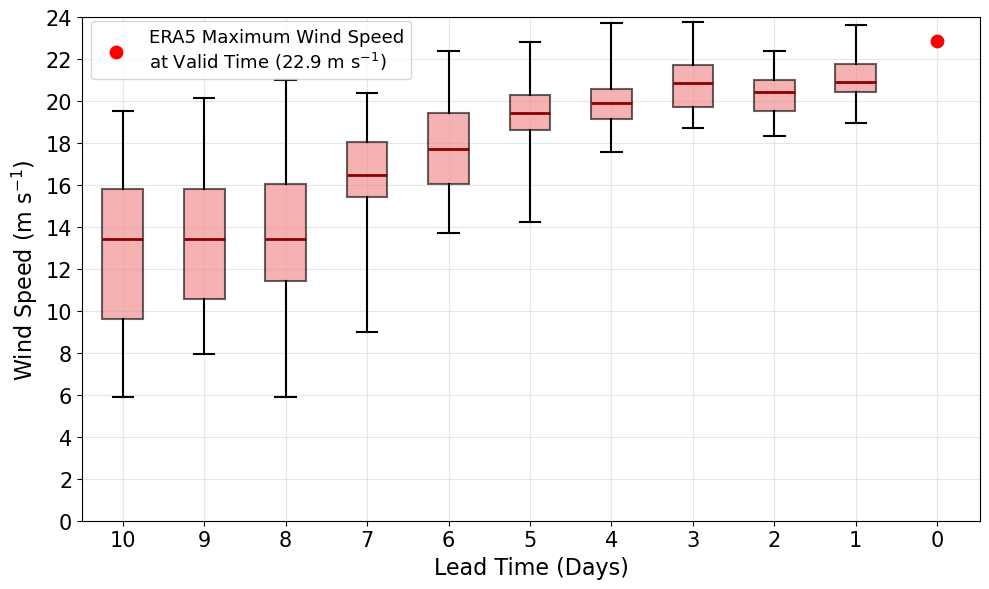

In [26]:
# Define search window around ERA5 maximum (in degrees)
search_radius_lat = 2.0  # ±2.0° latitude
search_radius_lon = 2.0  # ±2.0° longitude

lat_min = lat_max_ERA5_sfc - search_radius_lat
lat_max = lat_max_ERA5_sfc + search_radius_lat
lon_min = lon_max_aifs_sfc - search_radius_lon
lon_max = lon_max_aifs_sfc + search_radius_lon

# Extract wind speed within the search window for all ensemble
# members and lead times
ds_AIFS_search_window = ds_AIFS_sfc["wind_speed"].where(
    (
        (ds_AIFS_sfc["latitude"] >= lat_min)
        & (ds_AIFS_sfc["latitude"] <= lat_max)
        & (ds_AIFS_sfc["longitude"] >= lon_min)
        & (ds_AIFS_sfc["longitude"] <= lon_max)
    ),
    drop=True
)

# Find maximum wind speed within the search window for each
# ensemble member and lead time
aifs_wind_speed_max_in_window = ds_AIFS_search_window.max(
    dim=["latitude", "longitude"]
)


fig, ax = plt.subplots(figsize=(10, 6))

leadtimes = np.arange(1, 10 + 1, 1)
n_leads = len(leadtimes)

# Reverse data so lead time 10 days appears first
data_reversed = aifs_wind_speed_max_in_window.values[:, ::-1]

box = ax.boxplot(
    data_reversed,
    positions=np.arange(1, n_leads + 1),
    whis=[0, 100],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(
        facecolor="lightcoral",
        alpha=0.6,
        linewidth=1.5
    ),
    medianprops=dict(
        color="darkred",
        linewidth=2
    ),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5)
)

# ERA5 point: maximum surface wind speed
ax.scatter(
    n_leads + 1,
    wind_speed_max_ERA5_sfc,
    color="red",
    marker="o",
    s=80,
    zorder=5,
    label=(
        "ERA5 Maximum Wind Speed\n"
        f"at Valid Time ({wind_speed_max_ERA5_sfc:.1f} "
        "m s$^{-1}$)"
    )
)

# Tick labels
xtick_positions = np.arange(1, n_leads + 2)
xtick_labels = list(leadtimes[::-1]) + [0]

ax.set_xticks(xtick_positions)
ax.set_xticklabels(xtick_labels, fontsize=15)
ax.tick_params(axis="y", labelsize=15)

# Fixed y-axis from 0 to 24 m s^-1
ax.set_ylim(0, 24)
ax.set_yticks(np.arange(0, 24 + 2, 2))

valid_time = pd.to_datetime(
    aifs_wind_speed_max_in_window["fc_valid_time"].values[0]
)
time_str = valid_time.strftime("%Y-%m-%d %H:%M")

ax.set_xlabel("Lead Time (Days)", fontsize=16)
ax.set_ylabel("Wind Speed (m s$^{-1}$)", fontsize=16)

ax.legend(
    fontsize=13,
    loc="upper left",
    bbox_to_anchor=(0.0, 1.01)
)

ax.set_axisbelow(True)
ax.grid(alpha=0.3)

fig.tight_layout()

png_path, pdf_path = save_plot(
    fig,
    "boxplot_sfc_AIFS_ERA5_max_spatial_allowance"
)

plt.show()
plt.close(fig)

#### **Boxplot comparing AIFS ensemble wind speeds at 500 hPa with max. wind speed in ERA5**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_boxplot_500hPa_AIFS_ERA5_max.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_boxplot_500hPa_AIFS_ERA5_max.pdf


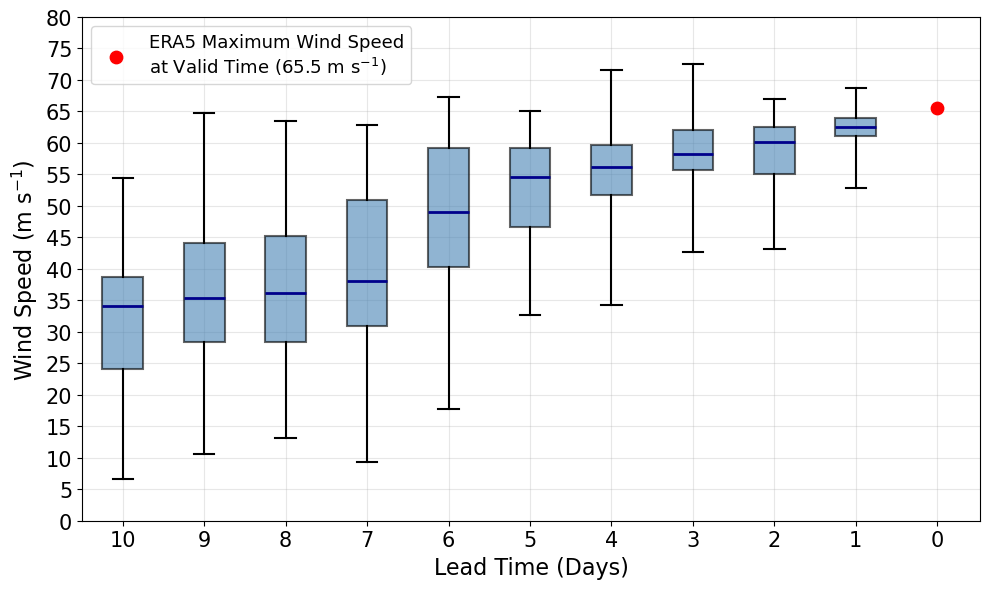

In [27]:
fig, ax = plt.subplots(figsize=(10, 6))

# AIFS 500 hPa wind at ERA5 500 hPa maximum (nearest AIFS grid point)
lon_max_aifs_500hpa = lon_max_500hPa_ERA5_pl % 360
ds_AIFS_pl_sel_wind_speed = ds_AIFS_pl["wind_speed"].sel(
    isobaricInhPa=500,
    latitude=lat_max_500hPa_ERA5_pl,
    longitude=lon_max_aifs_500hpa,
    method="nearest"
)

# Use actual leadtime coordinate (robust, no hardcoding)
leadtimes = ds_AIFS_pl_sel_wind_speed["leadtime"].values
n_leads = len(leadtimes)

# Convert leadtime labels to days when stored as timedelta64
if np.issubdtype(leadtimes.dtype, np.timedelta64):
    leadtime_days = (leadtimes / np.timedelta64(1, "D")).astype(int)
else:
    leadtime_days = leadtimes.astype(int)

# Build one array per leadtime explicitly (robust to dimension order)
data_for_boxplot = [
    np.ravel(ds_AIFS_pl_sel_wind_speed.sel(leadtime=lt).values)
    for lt in leadtimes[::-1]
]

box = ax.boxplot(
    data_for_boxplot,
    positions=np.arange(1, n_leads + 1),
    whis=[0, 100],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(facecolor="steelblue", alpha=0.6, linewidth=1.5),
    medianprops=dict(color="darkblue", linewidth=2),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5)
)

# ERA5 point (maximum 500 hPa wind speed)
ax.scatter(
    n_leads + 1,
    wind_speed_max_500hPa_ERA5_pl,
    color="red",
    marker="o",
    s=80,
    zorder=5,
    label=(
        "ERA5 Maximum Wind Speed\n"
        f"at Valid Time ({wind_speed_max_500hPa_ERA5_pl:.1f} "
        "m s$^{-1}$)"
    )
)

# Tick labels
xtick_positions = np.arange(1, n_leads + 2)
xtick_labels = list(leadtime_days[::-1]) + [0]

ax.set_xticks(xtick_positions)
ax.set_xticklabels(xtick_labels, fontsize=15)
ax.tick_params(axis="y", labelsize=15)

valid_time = pd.to_datetime(ds_AIFS_pl["fc_valid_time"].values[0])
time_str = valid_time.strftime("%Y-%m-%d %H:%M")

ax.set_xlabel("Lead Time (Days)", fontsize=16)
ax.set_ylabel("Wind Speed (m s$^{-1}$)", fontsize=16)

# Simple, readable y-axis
y_all = np.concatenate([
    np.concatenate(data_for_boxplot),
    np.array([wind_speed_max_500hPa_ERA5_pl])
])
y_low = max(0, 5 * np.floor(np.nanmin(y_all) / 5) - 5)
y_high = 5 * np.ceil(np.nanmax(y_all) / 5) + 5

ax.set_ylim(y_low, y_high)
ax.set_yticks(np.arange(y_low, y_high + 0.1, 5))

ax.legend(fontsize=13, loc="upper left")
ax.set_axisbelow(True)
ax.grid(alpha=0.3)

fig.tight_layout()

png_path, pdf_path = save_plot(
    fig,
    "boxplot_500hPa_AIFS_ERA5_max"
)

plt.show()
plt.close(fig)

#### **Boxplot comparing AIFS ensemble wind speeds at 500 hPa with max. 500 hPa wind speed in ERA5 with spatial shift allowance - AIFS finds max. wind speeds within ±2.0° lat, ±2.0° lon of the ERA5 maximum location**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_boxplot_500hPa_AIFS_ERA5_max_spatial_allowance.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_boxplot_500hPa_AIFS_ERA5_max_spatial_allowance.pdf


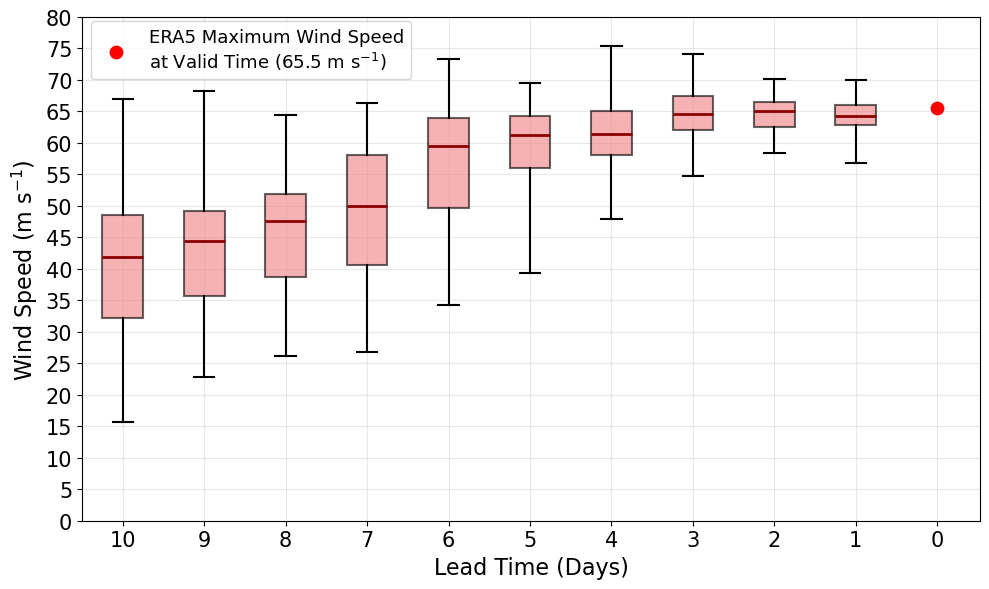

In [28]:
# Define search window around ERA5 500 hPa maximum
search_radius_lat = 2.0  # ±2.0° latitude
search_radius_lon = 2.0  # ±2.0° longitude

lat_center = lat_max_500hPa_ERA5_pl
lon_center = lon_max_500hPa_ERA5_pl % 360

lat_min = lat_center - search_radius_lat
lat_max = lat_center + search_radius_lat

# Select 500 hPa wind speed
ds_AIFS_500hPa_wind_speed = ds_AIFS_pl["wind_speed"].sel(
    isobaricInhPa=500,
    method="nearest"
)

# Circular longitude distance, robust around 0°/360°
lon_distance = np.abs(
    ((ds_AIFS_500hPa_wind_speed["longitude"] - lon_center + 180) % 360) - 180
)

# Extract wind speed within the search window for all ensemble members
# and lead times
ds_AIFS_500hPa_search_window = ds_AIFS_500hPa_wind_speed.where(
    (
        (ds_AIFS_500hPa_wind_speed["latitude"] >= lat_min)
        & (ds_AIFS_500hPa_wind_speed["latitude"] <= lat_max)
        & (lon_distance <= search_radius_lon)
    ),
    drop=True
)

# Maximum wind speed within the search window for each ensemble member
# and lead time
aifs_500hPa_wind_speed_max_in_window = (
    ds_AIFS_500hPa_search_window.max(
        dim=["latitude", "longitude"]
    )
)

fig, ax = plt.subplots(figsize=(10, 6))

# Use the actual lead-time coordinate
leadtimes = aifs_500hPa_wind_speed_max_in_window["leadtime"].values
n_leads = len(leadtimes)

# Convert lead-time labels to days when stored as timedelta64
if np.issubdtype(leadtimes.dtype, np.timedelta64):
    leadtime_days = (
        leadtimes / np.timedelta64(1, "D")
    ).astype(int)
else:
    leadtime_days = leadtimes.astype(int)

# Build one array per lead time, with longest lead time first
data_for_boxplot = []

for lt in leadtimes[::-1]:
    values = np.ravel(
        aifs_500hPa_wind_speed_max_in_window
        .sel(leadtime=lt)
        .values
    )

    # Remove possible missing values
    values = values[np.isfinite(values)]
    data_for_boxplot.append(values)

ax.boxplot(
    data_for_boxplot,
    positions=np.arange(1, n_leads + 1),
    whis=[0, 100],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(
        facecolor="lightcoral",
        alpha=0.6,
        linewidth=1.5
    ),
    medianprops=dict(
        color="darkred",
        linewidth=2
    ),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5)
)

# ERA5 point: maximum 500 hPa wind speed
ax.scatter(
    n_leads + 1,
    wind_speed_max_500hPa_ERA5_pl,
    color="red",
    marker="o",
    s=80,
    zorder=5,
    label=(
        "ERA5 Maximum Wind Speed\n"
        f"at Valid Time ({wind_speed_max_500hPa_ERA5_pl:.1f} "
        "m s$^{-1}$)"
    )
)

# Tick labels
xtick_positions = np.arange(1, n_leads + 2)
xtick_labels = list(leadtime_days[::-1]) + [0]

ax.set_xticks(xtick_positions)
ax.set_xticklabels(xtick_labels, fontsize=15)
ax.tick_params(axis="y", labelsize=15)

valid_time = pd.to_datetime(
    aifs_500hPa_wind_speed_max_in_window[
        "fc_valid_time"
    ].values[0]
)
time_str = valid_time.strftime("%Y-%m-%d %H:%M")

ax.set_xlabel("Lead Time (Days)", fontsize=16)
ax.set_ylabel("Wind Speed (m s$^{-1}$)", fontsize=16)

# Use the same y-axis scale as the first plot
ax.set_ylim(0, 80)
ax.set_yticks(np.arange(0, 80 + 5, 5))

ax.legend(
    fontsize=13,
    loc="upper left",
    bbox_to_anchor=(0.0, 1.01)
)

ax.set_axisbelow(True)
ax.grid(alpha=0.3)

fig.tight_layout()

# Save as PNG and PDF using the previously defined helper
png_path, pdf_path = save_plot(
    fig,
    "boxplot_500hPa_AIFS_ERA5_max_spatial_allowance"
)

plt.show()
plt.close(fig)

### **Spatial plots**

#### **Selection of South America subdomain**

In [29]:
ds_AIFS_sfc_sel = ds_AIFS_sfc.sel(
    latitude=slice(lat_max_ERA5_sfc + 5.5, lat_max_ERA5_sfc - 5.5),
    longitude=slice(lon_max_aifs_sfc - 7.0, lon_max_aifs_sfc + 7.0)
)

#### **Spatial plot of the surface wind at valid time for ERA5**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_spatial_plot_sfc_ERA5.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_spatial_plot_sfc_ERA5.pdf


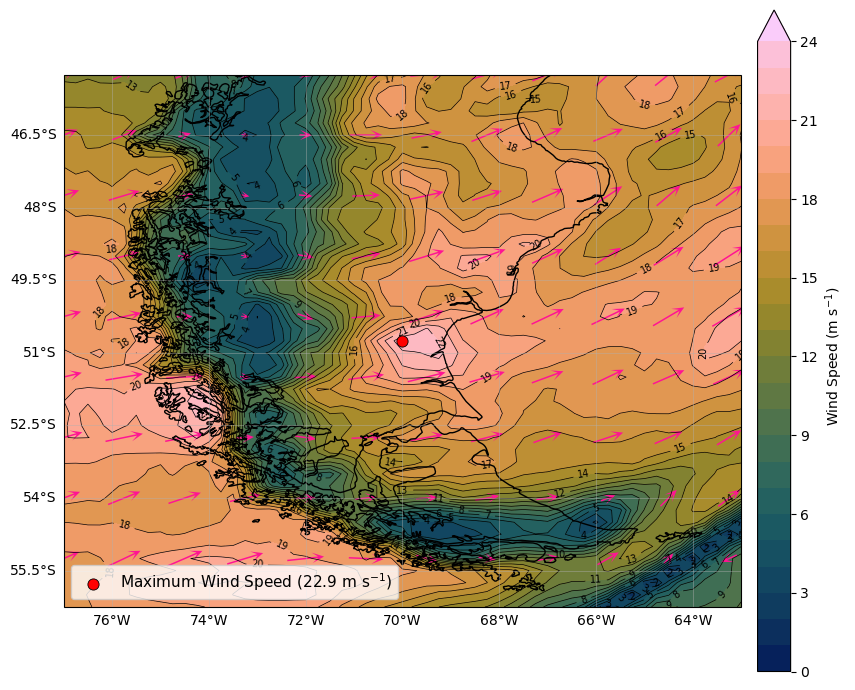

In [30]:
# Keep ERA5 map on the same domain as the AIFS surface subdomain

# Spatial extent from the selected AIFS surface domain
lat_min = float(ds_AIFS_sfc_sel.latitude.min())
lat_max = float(ds_AIFS_sfc_sel.latitude.max())
lon_min = float(ds_AIFS_sfc_sel.longitude.min())
lon_max = float(ds_AIFS_sfc_sel.longitude.max())

# Extract ERA5 variables and remove dimensions of length one
era5_ws = ds_ERA5_sfc["wind_speed"].squeeze()
era5_u = ds_ERA5_sfc["u10"].squeeze()
era5_v = ds_ERA5_sfc["v10"].squeeze()

# Convert ERA5 longitudes to 0–360 to match the AIFS convention
era5_ws = era5_ws.assign_coords(
    longitude=era5_ws.longitude % 360
).sortby("longitude")

era5_u = era5_u.assign_coords(
    longitude=era5_u.longitude % 360
).sortby("longitude")

era5_v = era5_v.assign_coords(
    longitude=era5_v.longitude % 360
).sortby("longitude")

# Select the same spatial domain as the AIFS surface plot
era5_ws_sel = era5_ws.sel(
    latitude=slice(lat_max, lat_min),
    longitude=slice(lon_min, lon_max)
)

era5_u_sel = era5_u.sel(
    latitude=slice(lat_max, lat_min),
    longitude=slice(lon_min, lon_max)
)

era5_v_sel = era5_v.sel(
    latitude=slice(lat_max, lat_min),
    longitude=slice(lon_min, lon_max)
)

# Find the actual ERA5 maximum within the displayed domain
era5_ws_stacked = era5_ws_sel.stack(
    gridpoint=("latitude", "longitude")
)

max_index = int(
    era5_ws_stacked.argmax(
        dim="gridpoint",
        skipna=True
    ).values
)

era5_max_point = era5_ws_stacked.isel(
    gridpoint=max_index
)

era5_max_value = float(era5_max_point.values)
era5_max_lat = float(era5_max_point["latitude"].values)
era5_max_lon = float(era5_max_point["longitude"].values)

# Create figure
fig = plt.figure(figsize=(9, 7))
ax = plt.axes(projection=ccrs.PlateCarree())

# Enforce the exact same spatial extent as the ensemble plots
ax.set_extent(
    [lon_min, lon_max, lat_min, lat_max],
    crs=ccrs.PlateCarree()
)

# Filled wind-speed contours
V_levels = np.arange(0, 25, 1)

cf = ax.contourf(
    era5_ws_sel.longitude,
    era5_ws_sel.latitude,
    era5_ws_sel,
    levels=V_levels,
    cmap="cmc.batlow",
    vmin=0,
    vmax=25,
    extend="max",
    transform=ccrs.PlateCarree()
)

# Wind-speed contour lines
cs = ax.contour(
    era5_ws_sel.longitude,
    era5_ws_sel.latitude,
    era5_ws_sel,
    levels=V_levels,
    colors="black",
    linewidths=0.5,
    transform=ccrs.PlateCarree()
)

ax.clabel(
    cs,
    inline=True,
    fontsize=7,
    fmt="%d"
)

# Wind vectors
q = ax.quiver(
    era5_u_sel.longitude[::5],
    era5_u_sel.latitude[::5],
    era5_u_sel.values[::5, ::5],
    era5_v_sel.values[::5, ::5],
    color="deeppink",
    scale=350,
    width=0.0022,
    headwidth=7,
    headlength=8,
    headaxislength=4,
    pivot="mid",
    transform=ccrs.PlateCarree()
)

# Marker at the actual ERA5 maximum grid point
max_point = ax.scatter(
    era5_max_lon,
    era5_max_lat,
    color="red",
    edgecolor="black",
    linewidth=0.6,
    s=65,
    transform=ccrs.PlateCarree(),
    zorder=6
)

# Coastlines
ax.add_feature(cfeature.COASTLINE)

# Coordinate grid
gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.6,
    alpha=0.5
)

gl.top_labels = False
gl.right_labels = False

# Valid time
valid_time = pd.to_datetime(
    ds_ERA5_sfc["valid_time"].values
)

# Legend
ax.legend(
    [max_point],
    [
        f"Maximum Wind Speed "
        f"({era5_max_value:.1f} m s$^{{-1}}$)"
    ],
    loc="lower left",
    fontsize=11,
    frameon=True
)

# Color bar
cbar = fig.colorbar(
    cf,
    ax=ax,
    pad=0.02
)

cbar.set_label("Wind Speed (m s$^{-1}$)")

fig.tight_layout()

# Save as PNG and PDF using the existing helper function
png_path, pdf_path = save_plot(
    fig,
    "spatial_plot_sfc_ERA5"
)

plt.show()
plt.close(fig)

#### **Spatial plot of the wind at 500 hPa geopotential height at valid time for ERA5**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_spatial_plot_500hPa_ERA5.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_spatial_plot_500hPa_ERA5.pdf


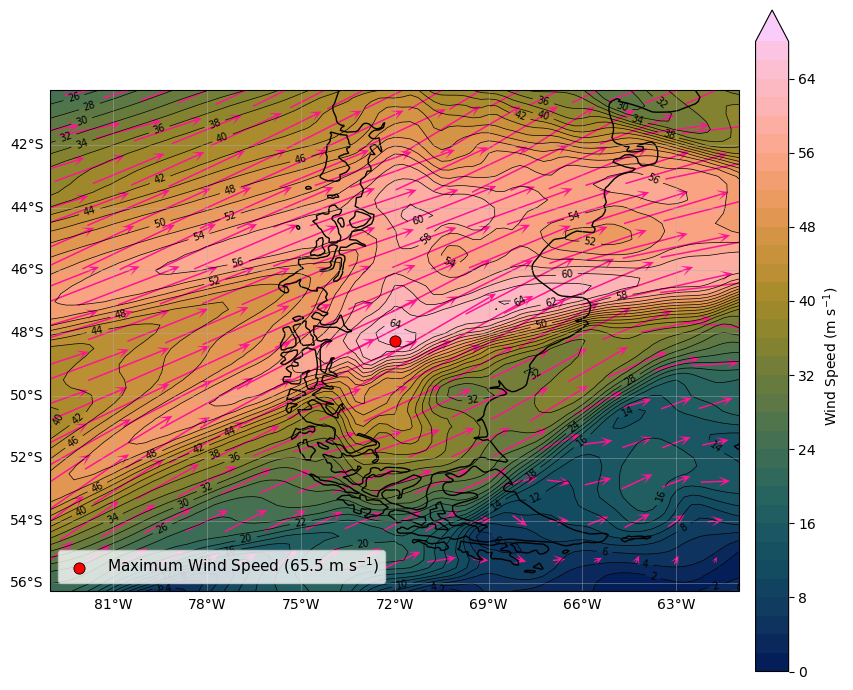

In [31]:
# Center the 500 hPa map on the previously determined
# ERA5 500 hPa maximum
lat_center = lat_max_500hPa_ERA5_pl
lon_center = lon_max_500hPa_ERA5_pl % 360

# Use the same overview padding as the ensemble plots
lat_pad = 8.0
lon_pad = 11.0

lat_min = lat_center - lat_pad
lat_max = lat_center + lat_pad
lon_min = lon_center - lon_pad
lon_max = lon_center + lon_pad

# ERA5 500 hPa wind speed and components
era5_ws = (
    ds_ERA5_pl["wind_speed"]
    .sel(isobaricInhPa=500, method="nearest")
    .squeeze()
)

era5_u = (
    ds_ERA5_pl["u"]
    .sel(isobaricInhPa=500, method="nearest")
    .squeeze()
)

era5_v = (
    ds_ERA5_pl["v"]
    .sel(isobaricInhPa=500, method="nearest")
    .squeeze()
)

# Convert ERA5 longitudes to 0–360 to match the AIFS convention
era5_ws = era5_ws.assign_coords(
    longitude=era5_ws.longitude % 360
).sortby("longitude")

era5_u = era5_u.assign_coords(
    longitude=era5_u.longitude % 360
).sortby("longitude")

era5_v = era5_v.assign_coords(
    longitude=era5_v.longitude % 360
).sortby("longitude")

# Select the same spatial domain as the AIFS 500 hPa plots
era5_ws_sel = era5_ws.sel(
    latitude=slice(lat_max, lat_min),
    longitude=slice(lon_min, lon_max)
)

era5_u_sel = era5_u.sel(
    latitude=slice(lat_max, lat_min),
    longitude=slice(lon_min, lon_max)
)

era5_v_sel = era5_v.sel(
    latitude=slice(lat_max, lat_min),
    longitude=slice(lon_min, lon_max)
)

# Find the actual ERA5 500 hPa wind-speed maximum
# within the displayed domain
era5_ws_stacked = era5_ws_sel.stack(
    gridpoint=("latitude", "longitude")
)

max_index = int(
    era5_ws_stacked.argmax(
        dim="gridpoint",
        skipna=True
    ).values
)

era5_max_point = era5_ws_stacked.isel(
    gridpoint=max_index
)

era5_max_value = float(era5_max_point.values)
era5_max_lat = float(era5_max_point["latitude"].values)
era5_max_lon = float(era5_max_point["longitude"].values)

# Create figure
fig = plt.figure(figsize=(9, 7))
ax = plt.axes(projection=ccrs.PlateCarree())

# Enforce the exact same spatial extent as the ensemble plots
ax.set_extent(
    [lon_min, lon_max, lat_min, lat_max],
    crs=ccrs.PlateCarree()
)

# Filled wind-speed contours
V_levels = np.arange(0, 70, 2)

cf = ax.contourf(
    era5_ws_sel.longitude,
    era5_ws_sel.latitude,
    era5_ws_sel,
    levels=V_levels,
    cmap="cmc.batlow",
    vmin=0,
    vmax=70,
    extend="max",
    transform=ccrs.PlateCarree()
)

# Wind-speed contour lines
cs = ax.contour(
    era5_ws_sel.longitude,
    era5_ws_sel.latitude,
    era5_ws_sel,
    levels=V_levels,
    colors="black",
    linewidths=0.5,
    transform=ccrs.PlateCarree()
)

ax.clabel(
    cs,
    inline=True,
    fontsize=7,
    fmt="%d"
)

# Wind vectors
q = ax.quiver(
    era5_u_sel.longitude[::5],
    era5_u_sel.latitude[::5],
    era5_u_sel.values[::5, ::5],
    era5_v_sel.values[::5, ::5],
    color="deeppink",
    scale=350,
    width=0.0022,
    headwidth=7,
    headlength=8,
    headaxislength=4,
    pivot="mid",
    transform=ccrs.PlateCarree()
)

# Marker at the actual ERA5 500 hPa maximum grid point
max_point_500 = ax.scatter(
    era5_max_lon,
    era5_max_lat,
    color="red",
    edgecolor="black",
    linewidth=0.6,
    s=65,
    transform=ccrs.PlateCarree(),
    zorder=6
)

# Coastlines
ax.add_feature(cfeature.COASTLINE)

# Coordinate grid
gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.6,
    alpha=0.5
)

gl.top_labels = False
gl.right_labels = False

# Valid time
valid_time = pd.to_datetime(
    ds_ERA5_pl["valid_time"].values
)

# Legend
ax.legend(
    [max_point_500],
    [
        f"Maximum Wind Speed "
        f"({era5_max_value:.1f} m s$^{{-1}}$)"
    ],
    loc="lower left",
    fontsize=11,
    frameon=True
)

# Color bar
cbar = fig.colorbar(
    cf,
    ax=ax,
    pad=0.02
)

cbar.set_label("Wind Speed (m s$^{-1}$)")

fig.tight_layout()

# Save as PNG and PDF using the existing helper function
png_path, pdf_path = save_plot(
    fig,
    "spatial_plot_500hPa_ERA5"
)

plt.show()
plt.close(fig)

#### **Ensemble mean spatial plot for different lead times with wind directions for surface wind of AIFS and ERA5 in comparison**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_spatial_plot_sfc_AIFS_ERA5_leadtimes.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_spatial_plot_sfc_AIFS_ERA5_leadtimes.pdf


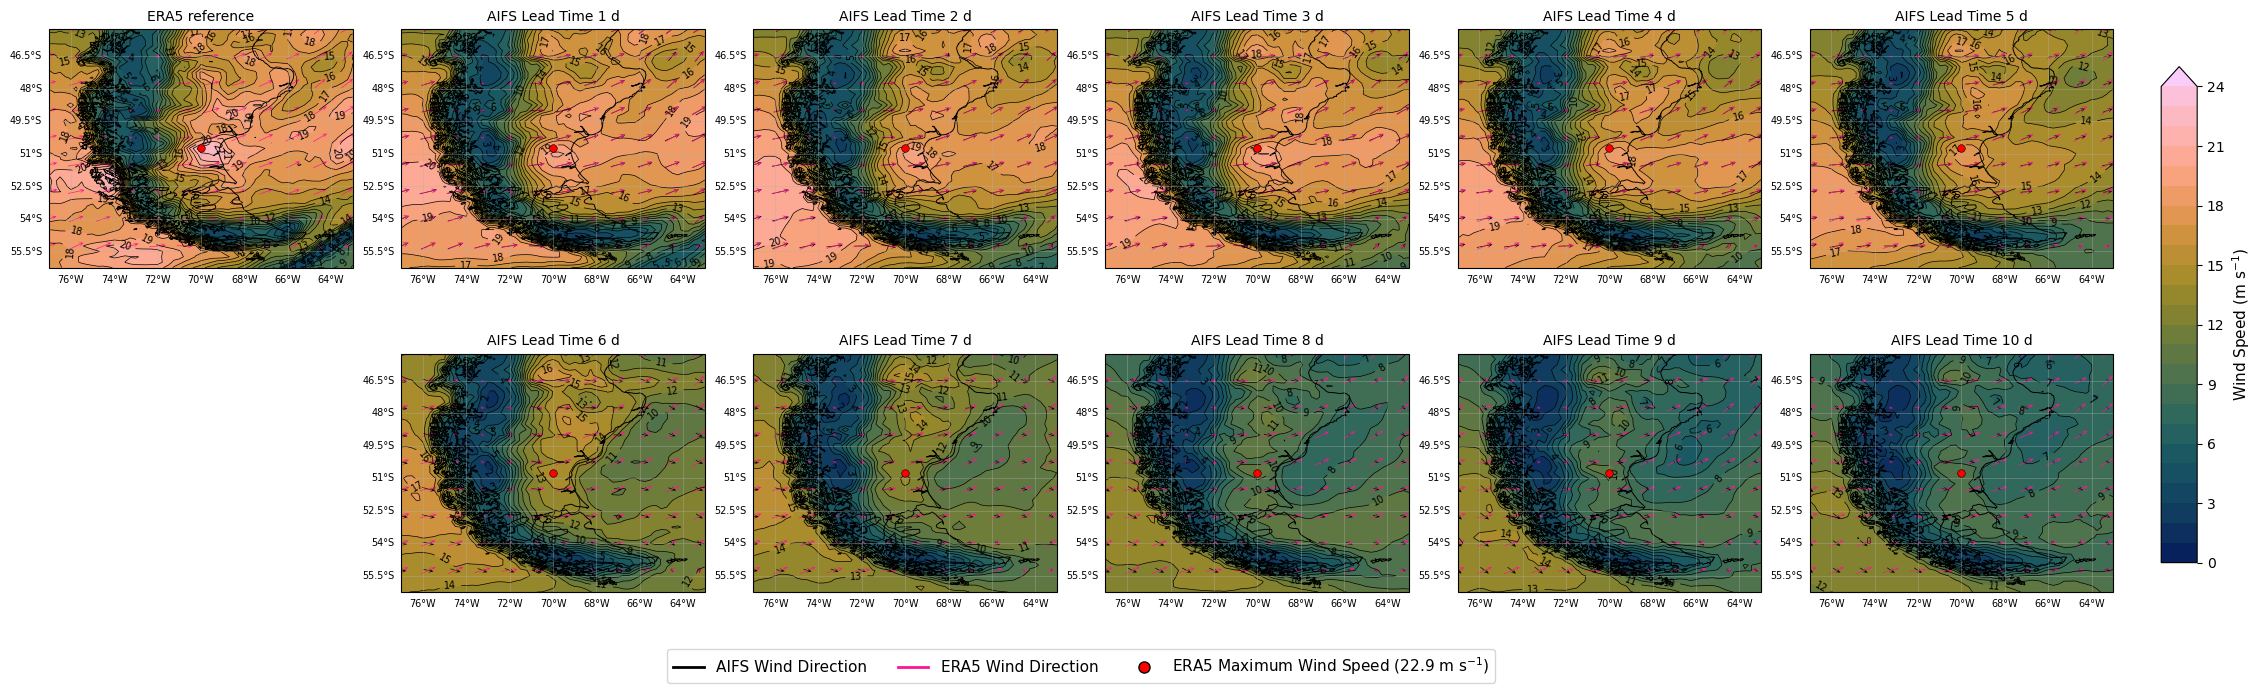

In [32]:
# Plot ERA5 reference plus AIFS lead times on the same domain:
# - ERA5 reference in the top-left panel
# - AIFS forecasts in the remaining panels
# - Bottom-left panel remains empty so the lower row is right-bound

# Ensemble mean over all members for the AIFS background and vectors
ens_mean = ds_AIFS_sfc_sel.mean(dim="ensemble_members")

# ------------------------------------------------------------------
# Prepare ERA5 data using the same longitude convention and domain
# ------------------------------------------------------------------

era5_ws = ds_ERA5_sfc["wind_speed"].squeeze()
era5_u = ds_ERA5_sfc["u10"].squeeze()
era5_v = ds_ERA5_sfc["v10"].squeeze()

# Convert ERA5 longitudes to 0–360 to match the AIFS convention
era5_ws = era5_ws.assign_coords(
    longitude=era5_ws.longitude % 360
).sortby("longitude")

era5_u = era5_u.assign_coords(
    longitude=era5_u.longitude % 360
).sortby("longitude")

era5_v = era5_v.assign_coords(
    longitude=era5_v.longitude % 360
).sortby("longitude")

# Spatial extent from the selected AIFS surface domain
lat_min = float(ds_AIFS_sfc_sel.latitude.min())
lat_max = float(ds_AIFS_sfc_sel.latitude.max())
lon_min = float(ds_AIFS_sfc_sel.longitude.min())
lon_max = float(ds_AIFS_sfc_sel.longitude.max())

# Select ERA5 data over the same spatial domain
era5_ws_sel = era5_ws.sel(
    latitude=slice(lat_max, lat_min),
    longitude=slice(lon_min, lon_max)
)

era5_u_sel = era5_u.sel(
    latitude=slice(lat_max, lat_min),
    longitude=slice(lon_min, lon_max)
)

era5_v_sel = era5_v.sel(
    latitude=slice(lat_max, lat_min),
    longitude=slice(lon_min, lon_max)
)

# ------------------------------------------------------------------
# Find the actual ERA5 maximum within the displayed domain
# ------------------------------------------------------------------

era5_ws_stacked = era5_ws_sel.stack(
    gridpoint=("latitude", "longitude")
)

max_index = int(
    era5_ws_stacked.argmax(
        dim="gridpoint",
        skipna=True
    ).values
)

era5_max_point = era5_ws_stacked.isel(
    gridpoint=max_index
)

era5_max_value = float(era5_max_point.values)
era5_max_lat = float(era5_max_point["latitude"].values)
era5_max_lon = float(era5_max_point["longitude"].values)

# ------------------------------------------------------------------
# Prepare lead-time labels
# ------------------------------------------------------------------

leadtimes = ens_mean["leadtime"].values
n_leadtimes = len(leadtimes)

if np.issubdtype(leadtimes.dtype, np.timedelta64):
    leadtime_days = (
        leadtimes / np.timedelta64(1, "D")
    ).astype(int)
else:
    leadtime_days = leadtimes.astype(int)

# This layout has space for ten AIFS lead times
if n_leadtimes > 10:
    raise ValueError(
        "The 2 × 6 layout supports a maximum of 10 AIFS lead times."
    )

# ------------------------------------------------------------------
# Valid time
# ------------------------------------------------------------------

valid_time = pd.to_datetime(
    np.asarray(ds_ERA5_sfc["valid_time"].values).squeeze()
)

# ------------------------------------------------------------------
# Create figure: 2 rows × 6 columns
# ------------------------------------------------------------------

map_projection = ccrs.PlateCarree()
V_levels = np.arange(0, 25, 1)

fig, axes = plt.subplots(
    2,
    6,
    figsize=(24, 8),
    subplot_kw={"projection": map_projection}
)

axes = axes.flatten()

# Panel arrangement:
#
# Top row:
# 0 = ERA5 reference
# 1–5 = AIFS lead times 1–5
#
# Bottom row:
# 6 = empty
# 7–11 = AIFS lead times 6–10
panel_indices_for_leadtimes = [
    1, 2, 3, 4, 5,
    7, 8, 9, 10, 11
]

# Leave space for:
# - the general title at the top
# - the shared legend at the bottom
# - the shared colorbar on the right
#
# Slightly increased horizontal spacing ensures that latitude labels
# stay with their respective subplot.
fig.subplots_adjust(
    left=0.04,
    right=0.90,
    bottom=0.13,
    top=0.86,
    wspace=0.16,
    hspace=0.25
)

# ------------------------------------------------------------------
# ERA5 reference panel
# ------------------------------------------------------------------

ax_ref = axes[0]

ax_ref.set_extent(
    [lon_min, lon_max, lat_min, lat_max],
    crs=map_projection
)

# ERA5 wind-speed background
cf = ax_ref.contourf(
    era5_ws_sel.longitude,
    era5_ws_sel.latitude,
    era5_ws_sel,
    levels=V_levels,
    cmap="cmc.batlow",
    vmin=0,
    vmax=25,
    extend="max",
    transform=map_projection
)

# ERA5 wind-speed contour lines
cs = ax_ref.contour(
    era5_ws_sel.longitude,
    era5_ws_sel.latitude,
    era5_ws_sel,
    levels=V_levels,
    colors="black",
    linewidths=0.5,
    transform=map_projection
)

ax_ref.clabel(
    cs,
    inline=True,
    fontsize=7,
    fmt="%d"
)

# ERA5 wind vectors
ax_ref.quiver(
    era5_u_sel.longitude[::5],
    era5_u_sel.latitude[::5],
    era5_u_sel.values[::5, ::5],
    era5_v_sel.values[::5, ::5],
    color="deeppink",
    scale=350,
    width=0.0022,
    headwidth=7,
    headlength=8,
    headaxislength=4,
    pivot="mid",
    transform=map_projection
)

# ERA5 maximum wind-speed location
ax_ref.scatter(
    era5_max_lon,
    era5_max_lat,
    color="red",
    edgecolor="black",
    linewidth=0.4,
    s=30,
    transform=map_projection,
    zorder=6
)

ax_ref.add_feature(
    cfeature.COASTLINE,
    linewidth=0.7
)

ax_ref.set_title(
    "ERA5 reference",
    fontsize=10
)

gl_ref = ax_ref.gridlines(
    draw_labels=True,
    linewidth=0.5,
    alpha=0.5
)

# Coordinates on both axes of the ERA5 panel
gl_ref.left_labels = True
gl_ref.bottom_labels = True
gl_ref.top_labels = False
gl_ref.right_labels = False

# Keep labels compact and close to their own subplot
gl_ref.xlabel_style = {"size": 7}
gl_ref.ylabel_style = {"size": 7}
gl_ref.xpadding = 5
gl_ref.ypadding = 5

# ------------------------------------------------------------------
# AIFS lead-time panels
# ------------------------------------------------------------------

for i, lt in enumerate(leadtimes):
    panel_index = panel_indices_for_leadtimes[i]
    ax = axes[panel_index]

    ds_sel = ens_mean.sel(leadtime=lt)

    ax.set_extent(
        [lon_min, lon_max, lat_min, lat_max],
        crs=map_projection
    )

    # AIFS ensemble-mean wind-speed background
    cf = ax.contourf(
        ds_sel.longitude,
        ds_sel.latitude,
        ds_sel["wind_speed"],
        levels=V_levels,
        cmap="cmc.batlow",
        vmin=0,
        vmax=25,
        extend="max",
        transform=map_projection
    )

    # AIFS wind-speed contour lines
    cs = ax.contour(
        ds_sel.longitude,
        ds_sel.latitude,
        ds_sel["wind_speed"],
        levels=V_levels,
        colors="black",
        linewidths=0.5,
        transform=map_projection
    )

    ax.clabel(
        cs,
        inline=True,
        fontsize=7,
        fmt="%d"
    )

    # AIFS ensemble-mean wind vectors
    ax.quiver(
        ds_sel.longitude[::5],
        ds_sel.latitude[::5],
        ds_sel["u10"][::5, ::5],
        ds_sel["v10"][::5, ::5],
        color="black",
        scale=350,
        width=0.0022,
        headwidth=7,
        headlength=8,
        headaxislength=4,
        pivot="mid",
        transform=map_projection
    )

    # ERA5 wind vectors for comparison
    ax.quiver(
        era5_u_sel.longitude[::5],
        era5_u_sel.latitude[::5],
        era5_u_sel.values[::5, ::5],
        era5_v_sel.values[::5, ::5],
        color="deeppink",
        scale=350,
        width=0.0022,
        headwidth=7,
        headlength=8,
        headaxislength=4,
        pivot="mid",
        transform=map_projection
    )

    # ERA5 maximum wind-speed location
    ax.scatter(
        era5_max_lon,
        era5_max_lat,
        color="red",
        edgecolor="black",
        linewidth=0.4,
        s=30,
        transform=map_projection,
        zorder=6
    )

    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.7
    )

    ax.set_title(
        f"AIFS Lead Time {leadtime_days[i]} d",
        fontsize=10
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        alpha=0.5
    )

    # Show latitude and longitude coordinates on every subplot
    gl.left_labels = True
    gl.bottom_labels = True
    gl.top_labels = False
    gl.right_labels = False

    # Keep coordinate labels compact and close to their own map
    gl.xlabel_style = {"size": 7}
    gl.ylabel_style = {"size": 7}
    gl.xpadding = 5
    gl.ypadding = 5

# ------------------------------------------------------------------
# Hide unused panels
# ------------------------------------------------------------------

# Always hide the bottom-left panel
axes[6].set_visible(False)

# Hide further unused AIFS panels if fewer than ten lead times exist
for panel_index in panel_indices_for_leadtimes[n_leadtimes:]:
    axes[panel_index].set_visible(False)

# ------------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------------

cbar_ax = fig.add_axes([
    0.92,   # left
    0.18,   # bottom
    0.015,  # width
    0.62    # height
])

cbar = fig.colorbar(
    cf,
    cax=cbar_ax,
    boundaries=V_levels,
    spacing="proportional",
    extend="max",
    extendfrac="auto"
)

cbar.set_label(
    "Wind Speed (m s$^{-1}$)",
    fontsize=11
)

cbar.ax.tick_params(labelsize=10)

# ------------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------------

legend_handles = [
    Line2D(
        [0],
        [0],
        color="black",
        linewidth=2,
        label="AIFS Wind Direction"
    ),
    Line2D(
        [0],
        [0],
        color="deeppink",
        linewidth=2,
        label="ERA5 Wind Direction"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor="red",
        markeredgecolor="black",
        markersize=8,
        label=(
            f"ERA5 Maximum Wind Speed "
            f"({era5_max_value:.1f} m s$^{{-1}}$)"
        )
    )
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.47, 0.02),
    ncol=3,
    fontsize=11,
    frameon=True
)

# ------------------------------------------------------------------
# Save as PNG and PDF using the existing helper function
# ------------------------------------------------------------------

png_path, pdf_path = save_plot(
    fig,
    "spatial_plot_sfc_AIFS_ERA5_leadtimes"
)

plt.show()
plt.close(fig)

#### **Ensemble mean spatial plot for different lead times with wind directions for wind at 500 hPa geopotential height of AIFS and ERA5 in comparison**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_spatial_plot_500hPa_AIFS_ERA5_leadtimes.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_spatial_plot_500hPa_AIFS_ERA5_leadtimes.pdf


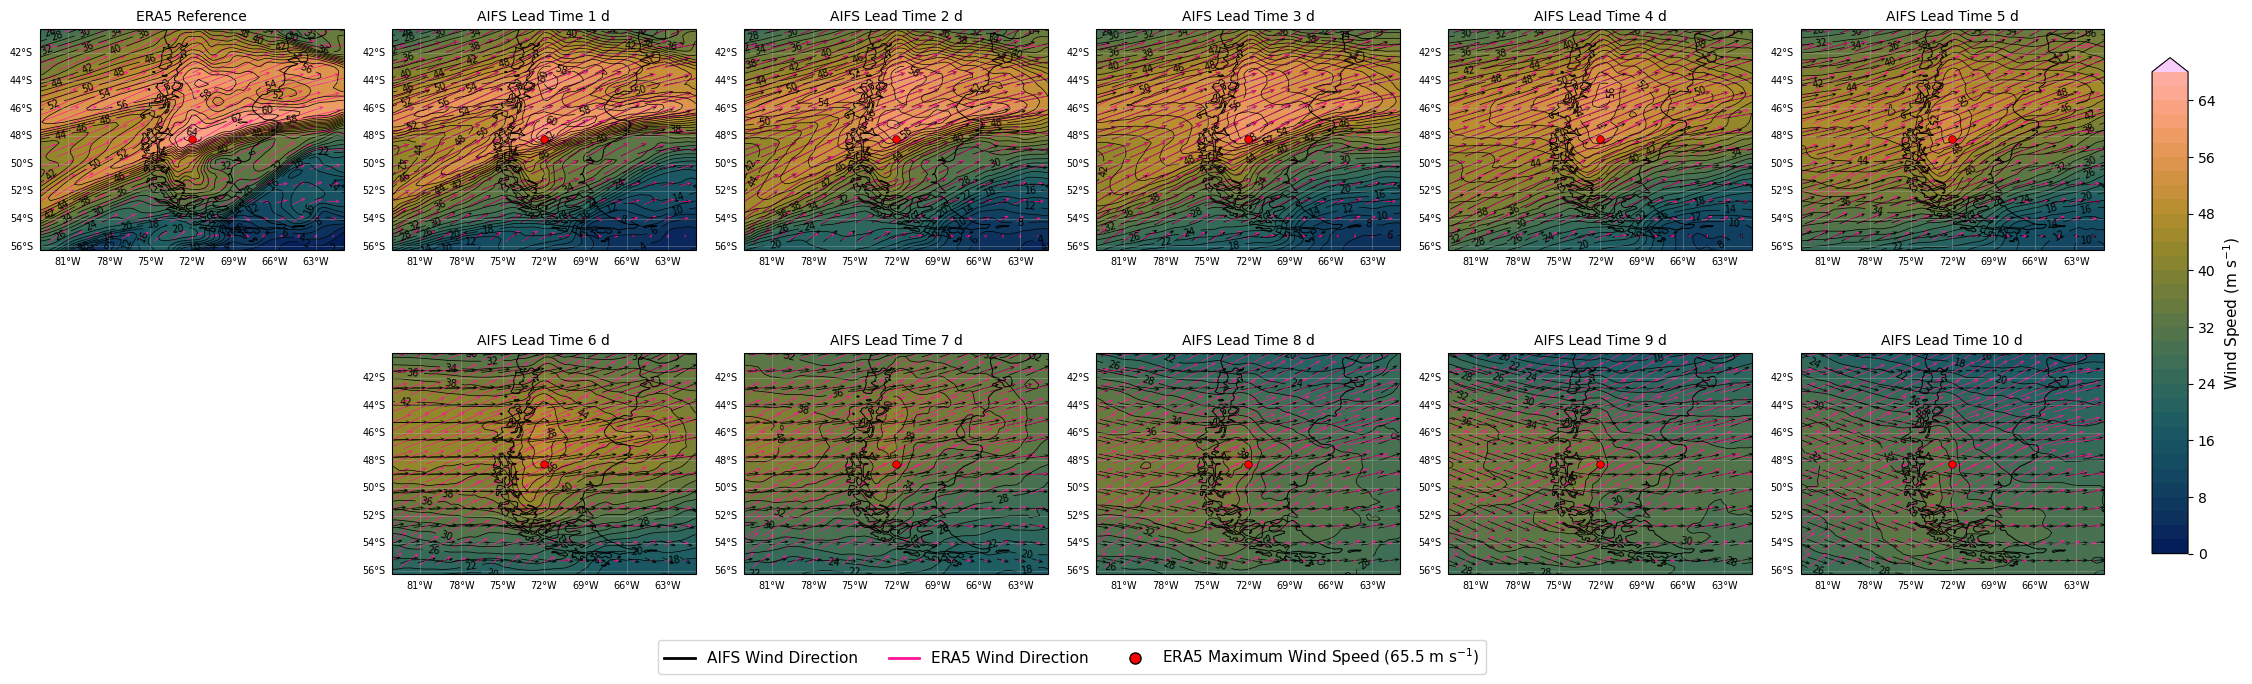

In [33]:
# Plot ERA5 reference plus AIFS lead times at 500 hPa:
# - ERA5 reference in the top-left panel
# - AIFS forecasts in the remaining panels
# - Bottom-left panel remains empty so the lower row is right-bound

# ------------------------------------------------------------------
# Select the 500 hPa level
# ------------------------------------------------------------------

# Select the AIFS 500 hPa level and the domain around
# the ERA5 500 hPa maximum

lat_pad = 8.0
lon_pad = 11.0

lat_center = lat_max_500hPa_ERA5_pl
lon_center = lon_max_500hPa_ERA5_pl % 360

lat_min_new = lat_center - lat_pad
lat_max_new = lat_center + lat_pad
lon_min_new = lon_center - lon_pad
lon_max_new = lon_center + lon_pad

ds_AIFS_500 = ds_AIFS_pl.sel(
    isobaricInhPa=500,
    method="nearest"
).sel(
    latitude=slice(lat_max_new, lat_min_new),
    longitude=slice(lon_min_new, lon_max_new)
)

# Select 500 hPa from ERA5
if "pressure_level" in ds_ERA5_pl.dims:
    ds_ERA5_500 = ds_ERA5_pl.sel(
        pressure_level=500,
        method="nearest"
    )
elif "isobaricInhPa" in ds_ERA5_pl.dims:
    ds_ERA5_500 = ds_ERA5_pl.sel(
        isobaricInhPa=500,
        method="nearest"
    )
elif "level" in ds_ERA5_pl.dims:
    ds_ERA5_500 = ds_ERA5_pl.sel(
        level=500,
        method="nearest"
    )
else:
    ds_ERA5_500 = ds_ERA5_pl

# Ensemble mean over all AIFS ensemble members
ens_mean = ds_AIFS_500.mean(
    dim="ensemble_members"
)

# ------------------------------------------------------------------
# Prepare ERA5 data using the same longitude convention and domain
# ------------------------------------------------------------------

era5_ws = ds_ERA5_500["wind_speed"].squeeze()
era5_u = ds_ERA5_500["u"].squeeze()
era5_v = ds_ERA5_500["v"].squeeze()

# Convert ERA5 longitudes to 0–360 to match the AIFS convention
era5_ws = era5_ws.assign_coords(
    longitude=era5_ws.longitude % 360
).sortby("longitude")

era5_u = era5_u.assign_coords(
    longitude=era5_u.longitude % 360
).sortby("longitude")

era5_v = era5_v.assign_coords(
    longitude=era5_v.longitude % 360
).sortby("longitude")

# Spatial extent from the selected AIFS 500 hPa domain
lat_min = float(ds_AIFS_500.latitude.min())
lat_max = float(ds_AIFS_500.latitude.max())
lon_min = float(ds_AIFS_500.longitude.min())
lon_max = float(ds_AIFS_500.longitude.max())

# Select ERA5 data over the same spatial domain
era5_ws_sel = era5_ws.sel(
    latitude=slice(lat_max, lat_min),
    longitude=slice(lon_min, lon_max)
)

era5_u_sel = era5_u.sel(
    latitude=slice(lat_max, lat_min),
    longitude=slice(lon_min, lon_max)
)

era5_v_sel = era5_v.sel(
    latitude=slice(lat_max, lat_min),
    longitude=slice(lon_min, lon_max)
)

# ------------------------------------------------------------------
# Find the actual ERA5 maximum within the displayed domain
# ------------------------------------------------------------------

era5_ws_stacked = era5_ws_sel.stack(
    gridpoint=("latitude", "longitude")
)

max_index = int(
    era5_ws_stacked.argmax(
        dim="gridpoint",
        skipna=True
    ).values
)

era5_max_point = era5_ws_stacked.isel(
    gridpoint=max_index
)

era5_max_value = float(era5_max_point.values)
era5_max_lat = float(
    era5_max_point["latitude"].values
)
era5_max_lon = float(
    era5_max_point["longitude"].values
)

# ------------------------------------------------------------------
# Prepare lead-time labels
# ------------------------------------------------------------------

leadtimes = ens_mean["leadtime"].values
n_leadtimes = len(leadtimes)

if np.issubdtype(
    leadtimes.dtype,
    np.timedelta64
):
    leadtime_days = (
        leadtimes / np.timedelta64(1, "D")
    ).astype(int)
else:
    leadtime_days = leadtimes.astype(int)

# This layout has space for ten AIFS lead times
if n_leadtimes > 10:
    raise ValueError(
        "The 2 × 6 layout supports a maximum of "
        "10 AIFS lead times."
    )

# ------------------------------------------------------------------
# Valid time
# ------------------------------------------------------------------

if "valid_time" in ds_ERA5_500.coords:
    valid_time = pd.to_datetime(
        np.asarray(
            ds_ERA5_500["valid_time"].values
        ).squeeze()
    )
elif "valid_time" in ds_ERA5_500:
    valid_time = pd.to_datetime(
        np.asarray(
            ds_ERA5_500["valid_time"].values
        ).squeeze()
    )
else:
    valid_time = pd.to_datetime(
        np.asarray(
            ds_ERA5_500["time"].values
        ).squeeze()
    )

# ------------------------------------------------------------------
# Create figure: 2 rows × 6 columns
# ------------------------------------------------------------------

map_projection = ccrs.PlateCarree()

# Wind-speed levels adapted for 500 hPa
V_levels = np.arange(0, 70, 2)

# Larger scale value because 500 hPa winds are generally stronger
quiver_scale = 350

fig, axes = plt.subplots(
    2,
    6,
    figsize=(24, 8),
    subplot_kw={
        "projection": map_projection
    }
)

axes = axes.flatten()

# Panel arrangement:
#
# Top row:
# 0 = ERA5 reference
# 1–5 = AIFS lead times 1–5
#
# Bottom row:
# 6 = empty
# 7–11 = AIFS lead times 6–10
panel_indices_for_leadtimes = [
    1, 2, 3, 4, 5,
    7, 8, 9, 10, 11
]

# Leave space for:
# - the general title at the top
# - the shared legend at the bottom
# - the shared colorbar on the right
#
# The horizontal spacing allows each panel to have its own
# latitude labels without entering the neighbouring map.
fig.subplots_adjust(
    left=0.04,
    right=0.90,
    bottom=0.13,
    top=0.86,
    wspace=0.16,
    hspace=0.25
)

# ------------------------------------------------------------------
# ERA5 reference panel
# ------------------------------------------------------------------

ax_ref = axes[0]

ax_ref.set_extent(
    [
        lon_min,
        lon_max,
        lat_min,
        lat_max
    ],
    crs=map_projection
)

# ERA5 wind-speed background
cf = ax_ref.contourf(
    era5_ws_sel.longitude,
    era5_ws_sel.latitude,
    era5_ws_sel,
    levels=V_levels,
    cmap="cmc.batlow",
    vmin=0,
    vmax=80,
    extend="max",
    transform=map_projection
)

# ERA5 wind-speed contour lines
cs = ax_ref.contour(
    era5_ws_sel.longitude,
    era5_ws_sel.latitude,
    era5_ws_sel,
    levels=V_levels,
    colors="black",
    linewidths=0.5,
    transform=map_projection
)

ax_ref.clabel(
    cs,
    inline=True,
    fontsize=7,
    fmt="%d"
)

# ERA5 wind vectors
ax_ref.quiver(
    era5_u_sel.longitude[::5],
    era5_u_sel.latitude[::5],
    era5_u_sel.values[::5, ::5],
    era5_v_sel.values[::5, ::5],
    color="deeppink",
    scale=quiver_scale,
    width=0.0022,
    headwidth=7,
    headlength=8,
    headaxislength=4,
    pivot="mid",
    transform=map_projection
)

# ERA5 maximum wind-speed location
ax_ref.scatter(
    era5_max_lon,
    era5_max_lat,
    color="red",
    edgecolor="black",
    linewidth=0.4,
    s=30,
    transform=map_projection,
    zorder=6
)

ax_ref.add_feature(
    cfeature.COASTLINE,
    linewidth=0.7
)

ax_ref.set_title(
    "ERA5 Reference",
    fontsize=10
)

gl_ref = ax_ref.gridlines(
    draw_labels=True,
    linewidth=0.5,
    alpha=0.5
)

# Coordinates on both axes of the ERA5 panel
gl_ref.left_labels = True
gl_ref.bottom_labels = True
gl_ref.top_labels = False
gl_ref.right_labels = False

# Coordinate-label formatting
gl_ref.xlabel_style = {
    "size": 7
}

gl_ref.ylabel_style = {
    "size": 7
}

gl_ref.xpadding = 5
gl_ref.ypadding = 5

# ------------------------------------------------------------------
# AIFS lead-time panels
# ------------------------------------------------------------------

for i, lt in enumerate(leadtimes):
    panel_index = (
        panel_indices_for_leadtimes[i]
    )

    ax = axes[panel_index]

    ds_sel = ens_mean.sel(
        leadtime=lt
    )

    ax.set_extent(
        [
            lon_min,
            lon_max,
            lat_min,
            lat_max
        ],
        crs=map_projection
    )

    # AIFS ensemble-mean 500 hPa wind-speed background
    cf = ax.contourf(
        ds_sel.longitude,
        ds_sel.latitude,
        ds_sel["wind_speed"],
        levels=V_levels,
        cmap="cmc.batlow",
        vmin=0,
        vmax=80,
        extend="max",
        transform=map_projection
    )

    # AIFS 500 hPa wind-speed contour lines
    cs = ax.contour(
        ds_sel.longitude,
        ds_sel.latitude,
        ds_sel["wind_speed"],
        levels=V_levels,
        colors="black",
        linewidths=0.5,
        transform=map_projection
    )

    ax.clabel(
        cs,
        inline=True,
        fontsize=7,
        fmt="%d"
    )

    # AIFS ensemble-mean 500 hPa wind vectors
    ax.quiver(
        ds_sel.longitude[::5],
        ds_sel.latitude[::5],
        ds_sel["u"][::5, ::5],
        ds_sel["v"][::5, ::5],
        color="black",
        scale=quiver_scale,
        width=0.0022,
        headwidth=7,
        headlength=8,
        headaxislength=4,
        pivot="mid",
        transform=map_projection
    )

    # ERA5 500 hPa wind vectors for comparison
    ax.quiver(
        era5_u_sel.longitude[::5],
        era5_u_sel.latitude[::5],
        era5_u_sel.values[::5, ::5],
        era5_v_sel.values[::5, ::5],
        color="deeppink",
        scale=quiver_scale,
        width=0.0022,
        headwidth=7,
        headlength=8,
        headaxislength=4,
        pivot="mid",
        transform=map_projection
    )

    # ERA5 maximum wind-speed location
    ax.scatter(
        era5_max_lon,
        era5_max_lat,
        color="red",
        edgecolor="black",
        linewidth=0.4,
        s=30,
        transform=map_projection,
        zorder=6
    )

    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.7
    )

    ax.set_title(
        f"AIFS Lead Time "
        f"{leadtime_days[i]} d",
        fontsize=10
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        alpha=0.5
    )

    # Show latitude and longitude coordinates
    # on every individual subplot
    gl.left_labels = True
    gl.bottom_labels = True
    gl.top_labels = False
    gl.right_labels = False

    # Coordinate-label formatting
    gl.xlabel_style = {
        "size": 7
    }

    gl.ylabel_style = {
        "size": 7
    }

    gl.xpadding = 5
    gl.ypadding = 5

# ------------------------------------------------------------------
# Hide unused panels
# ------------------------------------------------------------------

# Always hide the bottom-left panel
axes[6].set_visible(False)

# Hide further unused AIFS panels if fewer than ten lead times exist
for panel_index in panel_indices_for_leadtimes[
    n_leadtimes:
]:
    axes[panel_index].set_visible(False)

# ------------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------------

cbar_ax = fig.add_axes([
    0.92,   # left
    0.18,   # bottom
    0.015,  # width
    0.62    # height
])

cbar = fig.colorbar(
    cf,
    cax=cbar_ax,
    boundaries=V_levels,
    spacing="proportional",
    extend="max",
    extendfrac="auto"
)

cbar.set_label(
    "Wind Speed (m s$^{-1}$)",
    fontsize=11
)

cbar.ax.tick_params(
    labelsize=10
)

# ------------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------------

legend_handles = [
    Line2D(
        [0],
        [0],
        color="black",
        linewidth=2,
        label="AIFS Wind Direction"
    ),
    Line2D(
        [0],
        [0],
        color="deeppink",
        linewidth=2,
        label="ERA5 Wind Direction"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor="red",
        markeredgecolor="black",
        markersize=8,
        label=(
            "ERA5 Maximum Wind Speed "
            f"({era5_max_value:.1f} "
            "m s$^{-1}$)"
        )
    )
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.47, 0.02),
    ncol=3,
    fontsize=11,
    frameon=True
)

# ------------------------------------------------------------------
# Save as PNG and PDF using the existing helper function
# ------------------------------------------------------------------

png_path, pdf_path = save_plot(
    fig,
    "spatial_plot_500hPa_AIFS_ERA5_leadtimes"
)

plt.show()

#### **Overview maps**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_overview_map_sfc_ERA5.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_overview_map_sfc_ERA5.pdf


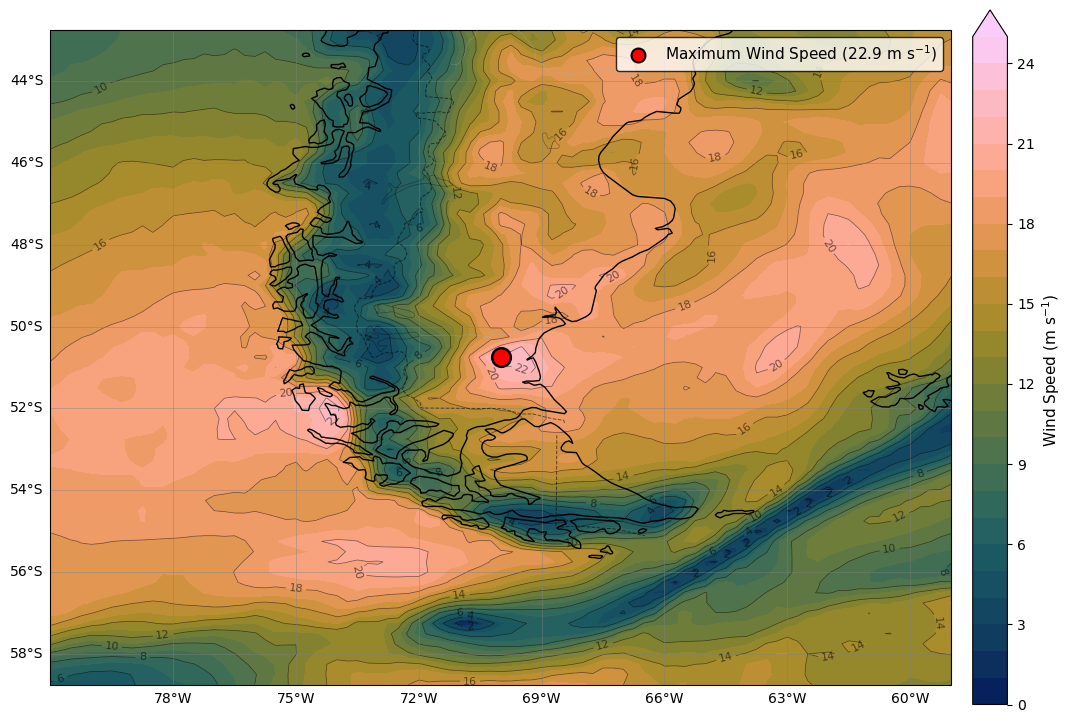

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_overview_map_500hPa_ERA5.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_overview_map_500hPa_ERA5.pdf


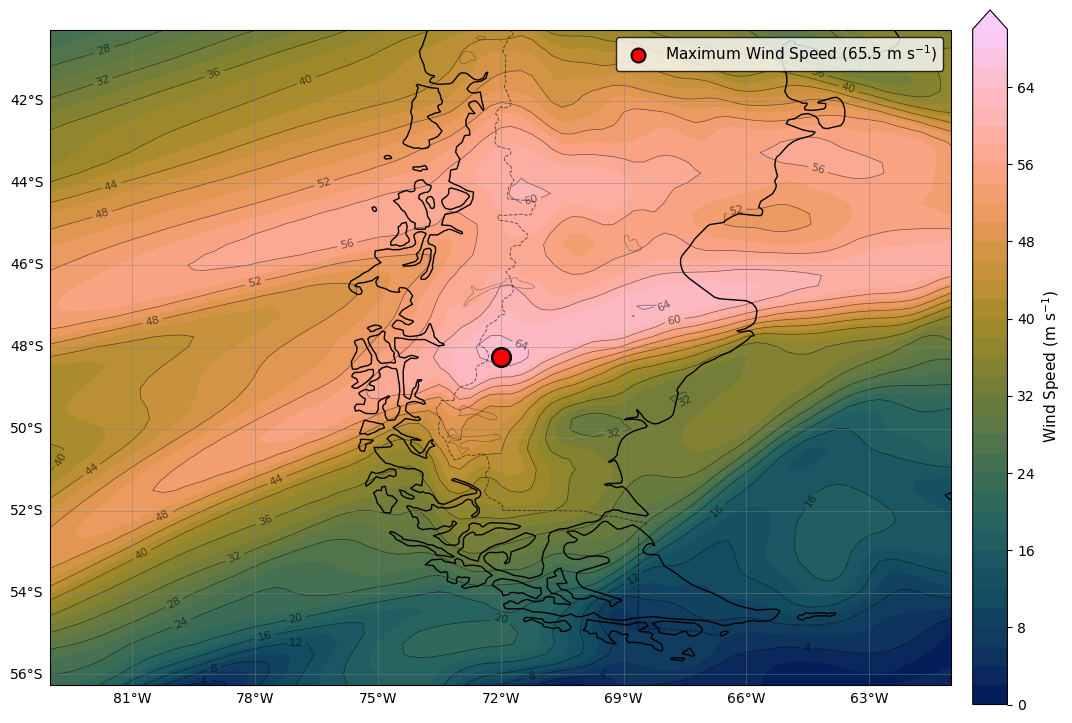

In [34]:
# Two separate ERA5 overview maps:
# one for surface wind and one for 500 hPa wind

# ------------------------------------------------------------------
# Prepare ERA5 wind speed fields
# ------------------------------------------------------------------

# Surface wind speed
era5_sfc_ws = ds_ERA5_sfc["wind_speed"].squeeze()

# 500 hPa wind components
era5_500_u = ds_ERA5_pl["u"].sel(
    isobaricInhPa=500,
    method="nearest"
).squeeze()

era5_500_v = ds_ERA5_pl["v"].sel(
    isobaricInhPa=500,
    method="nearest"
).squeeze()

# Calculate 500 hPa wind speed
era5_500_ws = np.hypot(
    era5_500_u,
    era5_500_v
)

era5_500_ws.name = "wind_speed"


# ------------------------------------------------------------------
# Extract valid times
# ------------------------------------------------------------------

def get_valid_time(dataset):
    """
    Extract the first available valid time from an xarray dataset.
    """

    if "valid_time" in dataset.coords or "valid_time" in dataset:
        time_values = np.asarray(
            dataset["valid_time"].values
        ).reshape(-1)

    elif "time" in dataset.coords or "time" in dataset:
        time_values = np.asarray(
            dataset["time"].values
        ).reshape(-1)

    else:
        raise KeyError(
            "No 'valid_time' or 'time' coordinate was found."
        )

    return pd.to_datetime(time_values[0])


valid_time_sfc = get_valid_time(ds_ERA5_sfc)
valid_time_500 = get_valid_time(ds_ERA5_pl)


# ------------------------------------------------------------------
# Function for the ERA5 overview maps
# ------------------------------------------------------------------

def plot_overview_map(
    background,
    lon_center,
    lat_center,
    lon_pad,
    lat_pad,
    max_lon,
    max_lat,
    max_speed,
    title,
    colorbar_label,
    level_step,
    levels_max,
    valid_time,
    plot_name
):
    """
    Plot an ERA5 wind speed overview map around the actual maximum.
    """

    bg = background.squeeze()

    # --------------------------------------------------------------
    # Use the 0–360 longitude convention consistently
    # --------------------------------------------------------------

    bg = bg.assign_coords(
        longitude=bg.longitude % 360
    ).sortby("longitude")

    lon_center = lon_center % 360
    max_lon = max_lon % 360

    # Spatial domain around the ERA5 maximum
    lon_min = lon_center - lon_pad
    lon_max = lon_center + lon_pad
    lat_min = lat_center - lat_pad
    lat_max = lat_center + lat_pad

    # Select the displayed domain
    bg_sel = bg.sel(
        longitude=slice(lon_min, lon_max),
        latitude=slice(lat_max, lat_min)
    )

    # --------------------------------------------------------------
    # Figure and map axis
    # --------------------------------------------------------------

    map_projection = ccrs.PlateCarree()

    fig, ax = plt.subplots(
        figsize=(14, 11),
        subplot_kw={
            "projection": map_projection
        }
    )

    ax.set_extent(
        [
            lon_min,
            lon_max,
            lat_min,
            lat_max
        ],
        crs=map_projection
    )

    # --------------------------------------------------------------
    # Wind speed background
    # --------------------------------------------------------------

    background_levels = np.arange(
        0,
        levels_max + level_step,
        level_step
    )

    cf = ax.contourf(
        bg_sel.longitude,
        bg_sel.latitude,
        bg_sel,
        levels=background_levels,
        cmap="cmc.batlow",
        vmin=0,
        vmax=levels_max,
        extend="max",
        transform=map_projection,
        zorder=1
    )

    # Wind speed contours
    cs = ax.contour(
        bg_sel.longitude,
        bg_sel.latitude,
        bg_sel,
        levels=background_levels[::2],
        colors="black",
        linewidths=0.5,
        alpha=0.55,
        transform=map_projection,
        zorder=2
    )

    ax.clabel(
        cs,
        inline=True,
        fontsize=8,
        fmt="%d"
    )

    # --------------------------------------------------------------
    # Geographic features
    # --------------------------------------------------------------

    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=1.0,
        zorder=3
    )

    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.7,
        linestyle="--",
        alpha=0.55,
        zorder=3
    )

    ax.add_feature(
        cfeature.LAKES,
        facecolor="none",
        edgecolor="black",
        linewidth=0.5,
        alpha=0.35,
        zorder=3
    )

    ax.add_feature(
        cfeature.RIVERS,
        linewidth=0.5,
        alpha=0.35,
        zorder=3
    )

    # --------------------------------------------------------------
    # Coordinate grid
    # --------------------------------------------------------------

    gl = ax.gridlines(
        draw_labels=True,
        dms=False,
        x_inline=False,
        y_inline=False,
        linewidth=0.6,
        color="gray",
        alpha=0.5,
        linestyle="-"
    )

    gl.left_labels = True
    gl.bottom_labels = True
    gl.top_labels = False
    gl.right_labels = False

    gl.xlabel_style = {
        "size": 10
    }

    gl.ylabel_style = {
        "size": 10
    }

    # Keep coordinate labels slightly separated from the map
    gl.xpadding = 5
    gl.ypadding = 5

    # --------------------------------------------------------------
    # ERA5 maximum marker
    # --------------------------------------------------------------

    ax.scatter(
        max_lon,
        max_lat,
        s=180,
        color="red",
        marker="o",
        edgecolor="black",
        linewidth=1.8,
        transform=map_projection,
        zorder=10
    )

    # --------------------------------------------------------------
    # Legend
    # --------------------------------------------------------------

    legend_handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="none",
            markerfacecolor="red",
            markeredgecolor="black",
            markeredgewidth=1.5,
            markersize=10,
            label=(
                "Maximum Wind Speed "
                f"({max_speed:.1f} m s$^{{-1}}$)"
            )
        )
    ]

    ax.legend(
        handles=legend_handles,
        loc="upper right",
        fontsize=11,
        frameon=True,
        edgecolor="black"
    )

    # --------------------------------------------------------------
    # Colorbar
    # --------------------------------------------------------------

    cbar = fig.colorbar(
        cf,
        ax=ax,
        pad=0.02,
        shrink=0.82,
        boundaries=background_levels,
        spacing="proportional",
        extend="max",
        extendfrac="auto"
    )

    cbar.set_label(
        colorbar_label,
        fontsize=11
    )

    cbar.ax.tick_params(
        labelsize=10
    )
    
    # --------------------------------------------------------------
    # Save as PNG and PDF
    # --------------------------------------------------------------

    png_path, pdf_path = save_plot(
        fig,
        plot_name
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------------
# ERA5 surface wind overview
# ------------------------------------------------------------------

plot_overview_map(
    background=era5_sfc_ws,
    lon_center=lon_max_ERA5_sfc,
    lat_center=lat_max_ERA5_sfc,
    lon_pad=11.0,
    lat_pad=8.0,
    max_lon=lon_max_ERA5_sfc,
    max_lat=lat_max_ERA5_sfc,
    max_speed=wind_speed_max_ERA5_sfc,
    title="ERA5 Surface Wind Speed Overview",
    colorbar_label="Wind Speed (m s$^{-1}$)",
    level_step=1,
    levels_max=25,
    valid_time=valid_time_sfc,
    plot_name="overview_map_sfc_ERA5"
)


# ------------------------------------------------------------------
# ERA5 500 hPa wind overview
# ------------------------------------------------------------------

plot_overview_map(
    background=era5_500_ws,
    lon_center=lon_max_500hPa_ERA5_pl,
    lat_center=lat_max_500hPa_ERA5_pl,
    lon_pad=11.0,
    lat_pad=8.0,
    max_lon=lon_max_500hPa_ERA5_pl,
    max_lat=lat_max_500hPa_ERA5_pl,
    max_speed=wind_speed_max_500hPa_ERA5_pl,
    title="ERA5 500 hPa Wind Speed Overview",
    colorbar_label="Wind Speed (m s$^{-1}$)",
    level_step=2,
    levels_max=70,
    valid_time=valid_time_500,
    plot_name="overview_map_500hPa_ERA5"
)

#### **Define one common spatial domain for all difference plots**

In [35]:
# Existing surface-wind domain
surface_lat_min_common = float(
    ds_AIFS_sfc_sel.latitude.min()
)

surface_lat_max_common = float(
    ds_AIFS_sfc_sel.latitude.max()
)

surface_lon_min_common = float(
    ds_AIFS_sfc_sel.longitude.min()
)

surface_lon_max_common = float(
    ds_AIFS_sfc_sel.longitude.max()
)

# Existing 500 hPa wind domain
lat_pad_500_diff = 8.0
lon_pad_500_diff = 11.0

lat_center_500_diff = lat_max_500hPa_ERA5_pl
lon_center_500_diff = lon_max_500hPa_ERA5_pl % 360

lat_min_500_domain = (
    lat_center_500_diff
    - lat_pad_500_diff
)

lat_max_500_domain = (
    lat_center_500_diff
    + lat_pad_500_diff
)

lon_min_500_domain = (
    lon_center_500_diff
    - lon_pad_500_diff
)

lon_max_500_domain = (
    lon_center_500_diff
    + lon_pad_500_diff
)

# Union of the surface and 500 hPa domains, rounded outward
# to whole degrees
common_lat_min_diff = float(
    np.floor(
        min(
            surface_lat_min_common,
            lat_min_500_domain
        )
    )
)

common_lat_max_diff = float(
    np.ceil(
        max(
            surface_lat_max_common,
            lat_max_500_domain
        )
    )
)

common_lon_min_diff = float(
    np.floor(
        min(
            surface_lon_min_common,
            lon_min_500_domain
        )
    )
)

common_lon_max_diff = float(
    np.ceil(
        max(
            surface_lon_max_common,
            lon_max_500_domain
        )
    )
)

#### **Difference plot for surface wind**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_difference_plot_sfc_AIFS_ERA5_leadtimes.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_difference_plot_sfc_AIFS_ERA5_leadtimes.pdf


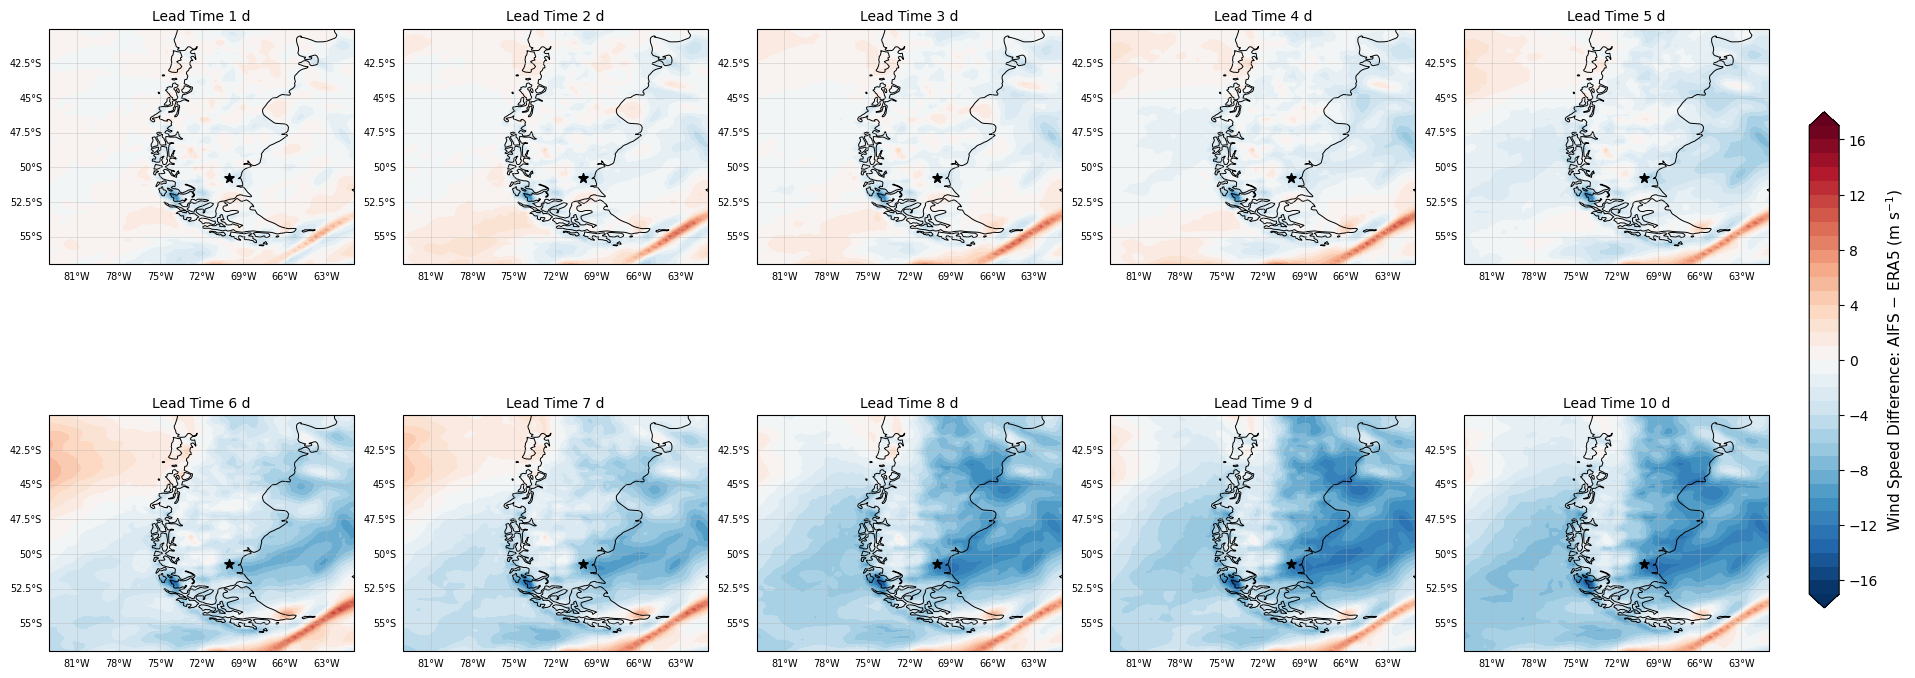

In [36]:
# Surface wind speed difference:
# AIFS ensemble mean minus ERA5
#
# Blue: AIFS ensemble mean is weaker than ERA5
# Red:  AIFS ensemble mean is stronger than ERA5

# ------------------------------------------------------------------
# Define the spatial extent for the surface wind difference plot
# ------------------------------------------------------------------

lat_min_sfc_diff = float(
    np.floor(
        min(
            float(
                ds_AIFS_sfc_sel.latitude.min()
            ),
            lat_max_500hPa_ERA5_pl - 8.0
        )
    )
)

lat_max_sfc_diff = float(
    np.ceil(
        max(
            float(
                ds_AIFS_sfc_sel.latitude.max()
            ),
            lat_max_500hPa_ERA5_pl + 8.0
        )
    )
)

lon_min_sfc_diff = float(
    np.floor(
        min(
            float(
                ds_AIFS_sfc_sel.longitude.min()
            ),
            (
                lon_max_500hPa_ERA5_pl % 360
            ) - 11.0
        )
    )
)

lon_max_sfc_diff = float(
    np.ceil(
        max(
            float(
                ds_AIFS_sfc_sel.longitude.max()
            ),
            (
                lon_max_500hPa_ERA5_pl % 360
            ) + 11.0
        )
    )
)

# Select the surface-wind field on the defined spatial domain
ds_AIFS_sfc_diff = ds_AIFS_sfc.sel(
    latitude=slice(
        lat_max_sfc_diff,
        lat_min_sfc_diff
    ),
    longitude=slice(
        lon_min_sfc_diff,
        lon_max_sfc_diff
    )
)

# ------------------------------------------------------------------
# AIFS ensemble mean on the common surface-wind subdomain
# ------------------------------------------------------------------

aifs_sfc_ens_mean_diff = (
    ds_AIFS_sfc_diff
    .mean(dim="ensemble_members")
    .sortby("leadtime")
    .squeeze(drop=True)
)

# ------------------------------------------------------------------
# Prepare ERA5 surface wind speed
# ------------------------------------------------------------------

era5_sfc_ws_diff = (
    ds_ERA5_sfc["wind_speed"]
    .squeeze(drop=True)
    .assign_coords(
        longitude=ds_ERA5_sfc["longitude"] % 360
    )
    .sortby("latitude")
    .sortby("longitude")
)

# ERA5 field on the displayed domain
era5_sfc_ws_domain_diff = era5_sfc_ws_diff.where(
    (
        (era5_sfc_ws_diff.latitude >= lat_min_sfc_diff)
        & (era5_sfc_ws_diff.latitude <= lat_max_sfc_diff)
        & (era5_sfc_ws_diff.longitude >= lon_min_sfc_diff)
        & (era5_sfc_ws_diff.longitude <= lon_max_sfc_diff)
    ),
    drop=True
)

# ------------------------------------------------------------------
# Interpolate ERA5 onto the AIFS grid
# ------------------------------------------------------------------

era5_sfc_ws_on_aifs_diff = era5_sfc_ws_diff.interp(
    latitude=aifs_sfc_ens_mean_diff.latitude,
    longitude=aifs_sfc_ens_mean_diff.longitude
)

# ------------------------------------------------------------------
# Calculate AIFS ensemble-mean minus ERA5 wind speed difference
# ------------------------------------------------------------------

sfc_wind_speed_difference = (
    aifs_sfc_ens_mean_diff["wind_speed"]
    - era5_sfc_ws_on_aifs_diff
).transpose(
    "leadtime",
    "latitude",
    "longitude"
)

sfc_wind_speed_difference.name = (
    "wind_speed_difference"
)

# Check that the interpolation produced valid values
n_finite_difference_values = int(
    np.isfinite(
        sfc_wind_speed_difference.values
    ).sum()
)

if n_finite_difference_values == 0:
    raise ValueError(
        "The ERA5-to-AIFS interpolation produced no "
        "finite values. Check the latitude and longitude "
        "coordinates."
    )

# ------------------------------------------------------------------
# Find the ERA5 maximum within the displayed domain
# ------------------------------------------------------------------

era5_sfc_ws_stacked_diff = (
    era5_sfc_ws_domain_diff.stack(
        gridpoint=(
            "latitude",
            "longitude"
        )
    )
)

era5_sfc_max_index_diff = int(
    era5_sfc_ws_stacked_diff.argmax(
        dim="gridpoint",
        skipna=True
    ).values
)

era5_sfc_max_point_diff = (
    era5_sfc_ws_stacked_diff.isel(
        gridpoint=era5_sfc_max_index_diff
    )
)

era5_sfc_max_value_diff = float(
    era5_sfc_max_point_diff.values
)

era5_sfc_max_lat_diff = float(
    era5_sfc_max_point_diff[
        "latitude"
    ].values
)

era5_sfc_max_lon_diff = float(
    era5_sfc_max_point_diff[
        "longitude"
    ].values
)

# ------------------------------------------------------------------
# Prepare lead-time labels
# ------------------------------------------------------------------

leadtimes_diff = (
    aifs_sfc_ens_mean_diff[
        "leadtime"
    ].values
)

n_leadtimes_diff = len(
    leadtimes_diff
)

if n_leadtimes_diff == 0:
    raise ValueError(
        "No AIFS lead times were found."
    )

if n_leadtimes_diff > 10:
    raise ValueError(
        "The 2 × 5 layout supports a maximum of "
        "10 AIFS lead times."
    )

if np.issubdtype(
    leadtimes_diff.dtype,
    np.timedelta64
):
    leadtime_days_diff = (
        leadtimes_diff
        / np.timedelta64(1, "D")
    ).astype(int)

else:
    leadtime_days_diff = (
        leadtimes_diff.astype(int)
    )

# ------------------------------------------------------------------
# Valid time
# ------------------------------------------------------------------

valid_time_diff = pd.to_datetime(
    np.asarray(
        ds_ERA5_sfc[
            "valid_time"
        ].values
    ).reshape(-1)[0]
)

# ------------------------------------------------------------------
# Create one common symmetric difference scale
# ------------------------------------------------------------------

difference_abs_max = float(
    np.abs(
        sfc_wind_speed_difference
    ).max(
        skipna=True
    ).compute().values
)

if not np.isfinite(
    difference_abs_max
):
    raise ValueError(
        "The surface-wind difference contains "
        "no finite values."
    )

# Round upward to the next whole m s^-1
difference_limit = max(
    1.0,
    float(
        np.ceil(
            difference_abs_max
        )
    )
)

difference_step = 1.0

difference_levels = np.arange(
    -difference_limit,
    difference_limit
    + difference_step,
    difference_step
)

# ------------------------------------------------------------------
# Create figure: 2 rows × 5 columns
# ------------------------------------------------------------------

map_projection = ccrs.PlateCarree()

fig, axes = plt.subplots(
    2,
    5,
    figsize=(20, 8),
    subplot_kw={
        "projection": map_projection
    }
)

axes = axes.flatten()

fig.subplots_adjust(
    left=0.04,
    right=0.90,
    bottom=0.08,
    top=0.95,
    wspace=0.16,
    hspace=0.25
)

# ------------------------------------------------------------------
# Difference panels
# ------------------------------------------------------------------

for i, lt in enumerate(
    leadtimes_diff
):
    ax = axes[i]

    difference_sel = (
        sfc_wind_speed_difference.sel(
            leadtime=lt
        )
    )

    ax.set_extent(
        [
            lon_min_sfc_diff,
            lon_max_sfc_diff,
            lat_min_sfc_diff,
            lat_max_sfc_diff
        ],
        crs=map_projection
    )

    # Wind speed difference background
    cf_diff = ax.contourf(
        difference_sel.longitude,
        difference_sel.latitude,
        difference_sel,
        levels=difference_levels,
        cmap="RdBu_r",
        extend="both",
        transform=map_projection
    )

    # ERA5 maximum wind speed location
    ax.scatter(
        era5_sfc_max_lon_diff,
        era5_sfc_max_lat_diff,
        marker="*",
        color="black",
        s=50,
        transform=map_projection,
        zorder=6
    )

    # Coastlines
    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.7
    )

    ax.set_title(
        f"Lead Time "
        f"{leadtime_days_diff[i]} d",
        fontsize=10
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        alpha=0.5
    )

    gl.left_labels = True
    gl.bottom_labels = True
    gl.top_labels = False
    gl.right_labels = False

    gl.xlabel_style = {
        "size": 7
    }

    gl.ylabel_style = {
        "size": 7
    }

    gl.xpadding = 5
    gl.ypadding = 5

# Hide unused panels if fewer than ten lead times exist
for panel_index in range(
    n_leadtimes_diff,
    len(axes)
):
    axes[
        panel_index
    ].set_visible(False)

# ------------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------------

cbar_ax = fig.add_axes([
    0.92,
    0.18,
    0.015,
    0.62
])

cbar = fig.colorbar(
    cf_diff,
    cax=cbar_ax,
    boundaries=difference_levels,
    spacing="proportional",
    extend="both",
    extendfrac="auto"
)

cbar.set_label(
    "Wind Speed Difference: AIFS − ERA5 (m s$^{-1}$)",
    fontsize=11
)

cbar.ax.tick_params(
    labelsize=10
)

# ------------------------------------------------------------------
# Save and display
# ------------------------------------------------------------------

png_path, pdf_path = save_plot(
    fig,
    "difference_plot_sfc_AIFS_ERA5_leadtimes"
)

plt.show()
plt.close(fig)

#### **Difference plot for 500 hPa wind**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_difference_plot_500hPa_AIFS_ERA5_leadtimes.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_difference_plot_500hPa_AIFS_ERA5_leadtimes.pdf


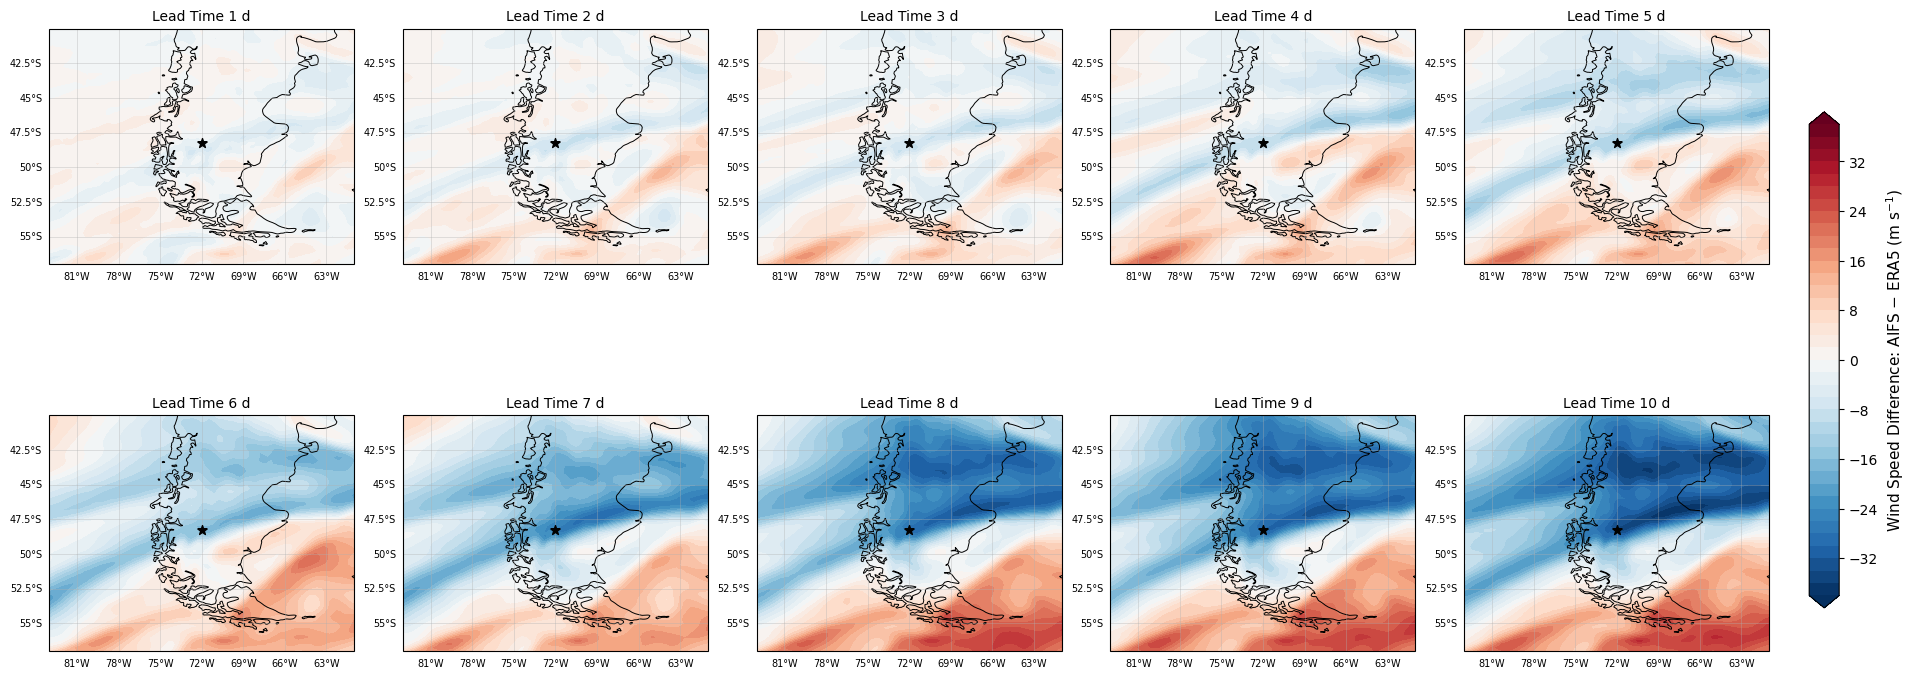

In [37]:
# 500 hPa wind speed difference:
# AIFS ensemble mean minus ERA5
#
# Blue: AIFS ensemble mean is weaker than ERA5
# Red:  AIFS ensemble mean is stronger than ERA5

# ------------------------------------------------------------------
# Select the AIFS 500 hPa field on the common map domain
# ------------------------------------------------------------------

ds_AIFS_500_diff = (
    ds_AIFS_pl["wind_speed"]
    .sel(
        isobaricInhPa=500,
        method="nearest"
    )
    .sel(
        latitude=slice(
            common_lat_max_diff,
            common_lat_min_diff
        ),
        longitude=slice(
            common_lon_min_diff,
            common_lon_max_diff
        )
    )
)

# ------------------------------------------------------------------
# AIFS ensemble mean
# ------------------------------------------------------------------

aifs_500_ens_mean_diff = (
    ds_AIFS_500_diff
    .mean(dim="ensemble_members")
    .sortby("leadtime")
    .squeeze(drop=True)
)

# ------------------------------------------------------------------
# Prepare ERA5 500 hPa wind speed
# ------------------------------------------------------------------

era5_500_ws_diff = (
    ds_ERA5_pl["wind_speed"]
    .sel(
        isobaricInhPa=500,
        method="nearest"
    )
    .squeeze(drop=True)
    .assign_coords(
        longitude=(
            ds_ERA5_pl["longitude"] % 360
        )
    )
    .sortby("latitude")
    .sortby("longitude")
)

# Use the exact common spatial extent
lat_min_500_diff = common_lat_min_diff
lat_max_500_diff = common_lat_max_diff
lon_min_500_diff = common_lon_min_diff
lon_max_500_diff = common_lon_max_diff

# ERA5 field on the displayed domain
era5_500_ws_domain_diff = (
    era5_500_ws_diff.where(
        (
            (
                era5_500_ws_diff.latitude
                >= lat_min_500_diff
            )
            & (
                era5_500_ws_diff.latitude
                <= lat_max_500_diff
            )
            & (
                era5_500_ws_diff.longitude
                >= lon_min_500_diff
            )
            & (
                era5_500_ws_diff.longitude
                <= lon_max_500_diff
            )
        ),
        drop=True
    )
)

# ------------------------------------------------------------------
# Interpolate ERA5 onto the AIFS grid
# ------------------------------------------------------------------

era5_500_ws_on_aifs_diff = (
    era5_500_ws_diff.interp(
        latitude=aifs_500_ens_mean_diff.latitude,
        longitude=aifs_500_ens_mean_diff.longitude
    )
)

# ------------------------------------------------------------------
# Calculate AIFS ensemble mean minus ERA5 wind speed difference
# ------------------------------------------------------------------

wind_speed_500_difference = (
    aifs_500_ens_mean_diff
    - era5_500_ws_on_aifs_diff
).transpose(
    "leadtime",
    "latitude",
    "longitude"
)

wind_speed_500_difference.name = (
    "wind_speed_500_difference"
)

# Check that the interpolation produced valid values
n_finite_500_difference_values = int(
    np.isfinite(
        wind_speed_500_difference.values
    ).sum()
)

if n_finite_500_difference_values == 0:
    raise ValueError(
        "The ERA5-to-AIFS interpolation produced no "
        "finite values. Check the latitude and longitude "
        "coordinates."
    )

# ------------------------------------------------------------------
# Find the ERA5 maximum within the displayed domain
# ------------------------------------------------------------------

era5_500_ws_stacked_diff = (
    era5_500_ws_domain_diff.stack(
        gridpoint=(
            "latitude",
            "longitude"
        )
    )
)

era5_500_max_index_diff = int(
    era5_500_ws_stacked_diff.argmax(
        dim="gridpoint",
        skipna=True
    ).values
)

era5_500_max_point_diff = (
    era5_500_ws_stacked_diff.isel(
        gridpoint=era5_500_max_index_diff
    )
)

era5_500_max_value_diff = float(
    era5_500_max_point_diff.values
)

era5_500_max_lat_diff = float(
    era5_500_max_point_diff[
        "latitude"
    ].values
)

era5_500_max_lon_diff = float(
    era5_500_max_point_diff[
        "longitude"
    ].values
)

# ------------------------------------------------------------------
# Prepare lead-time labels
# ------------------------------------------------------------------

leadtimes_500_diff = (
    aifs_500_ens_mean_diff[
        "leadtime"
    ].values
)

n_leadtimes_500_diff = len(
    leadtimes_500_diff
)

if n_leadtimes_500_diff == 0:
    raise ValueError(
        "No AIFS lead times were found."
    )

if n_leadtimes_500_diff > 10:
    raise ValueError(
        "The 2 × 5 layout supports a maximum of "
        "10 AIFS lead times."
    )

if np.issubdtype(
    leadtimes_500_diff.dtype,
    np.timedelta64
):
    leadtime_days_500_diff = (
        leadtimes_500_diff
        / np.timedelta64(1, "D")
    ).astype(int)

else:
    leadtime_days_500_diff = (
        leadtimes_500_diff.astype(int)
    )

# ------------------------------------------------------------------
# Valid time
# ------------------------------------------------------------------

valid_time_500_diff = pd.to_datetime(
    np.asarray(
        ds_ERA5_pl[
            "valid_time"
        ].values
    ).reshape(-1)[0]
)

# ------------------------------------------------------------------
# Create one common symmetric difference scale
# ------------------------------------------------------------------

difference_abs_max_500 = float(
    np.abs(
        wind_speed_500_difference
    ).max(
        skipna=True
    ).compute().values
)

if not np.isfinite(
    difference_abs_max_500
):
    raise ValueError(
        "The 500 hPa wind speed difference contains "
        "no finite values."
    )

# Use 2 m s^-1 intervals
difference_step_500 = 2.0

# Round upward to the next multiple of 2 m s^-1
difference_limit_500 = max(
    difference_step_500,
    float(
        difference_step_500
        * np.ceil(
            difference_abs_max_500
            / difference_step_500
        )
    )
)

difference_levels_500 = np.arange(
    -difference_limit_500,
    difference_limit_500
    + difference_step_500,
    difference_step_500
)

# ------------------------------------------------------------------
# Create figure: 2 rows × 5 columns
# ------------------------------------------------------------------

map_projection = ccrs.PlateCarree()

fig, axes = plt.subplots(
    2,
    5,
    figsize=(20, 8),
    subplot_kw={
        "projection": map_projection
    }
)

axes = axes.flatten()

fig.subplots_adjust(
    left=0.04,
    right=0.90,
    bottom=0.08,
    top=0.95,
    wspace=0.16,
    hspace=0.25
)

# ------------------------------------------------------------------
# Difference panels
# ------------------------------------------------------------------

for i, lt in enumerate(
    leadtimes_500_diff
):
    ax = axes[i]

    difference_500_sel = (
        wind_speed_500_difference.sel(
            leadtime=lt
        )
    )

    ax.set_extent(
        [
            common_lon_min_diff,
            common_lon_max_diff,
            common_lat_min_diff,
            common_lat_max_diff
        ],
        crs=map_projection
    )

    # Wind speed difference background
    cf_500_diff = ax.contourf(
        difference_500_sel.longitude,
        difference_500_sel.latitude,
        difference_500_sel,
        levels=difference_levels_500,
        cmap="RdBu_r",
        extend="both",
        transform=map_projection
    )

    # ERA5 maximum wind speed location
    ax.scatter(
        era5_500_max_lon_diff,
        era5_500_max_lat_diff,
        marker="*",
        color="black",
        s=50,
        transform=map_projection,
        zorder=6
    )

    # Coastlines
    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.7
    )

    ax.set_title(
        f"Lead Time "
        f"{leadtime_days_500_diff[i]} d",
        fontsize=10
    )

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.5,
        alpha=0.5
    )

    gl.left_labels = True
    gl.bottom_labels = True
    gl.top_labels = False
    gl.right_labels = False

    gl.xlabel_style = {
        "size": 7
    }

    gl.ylabel_style = {
        "size": 7
    }

    gl.xpadding = 5
    gl.ypadding = 5

# Hide unused panels if fewer than ten lead times exist
for panel_index in range(
    n_leadtimes_500_diff,
    len(axes)
):
    axes[
        panel_index
    ].set_visible(False)

# ------------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------------

cbar_ax = fig.add_axes([
    0.92,
    0.18,
    0.015,
    0.62
])

cbar = fig.colorbar(
    cf_500_diff,
    cax=cbar_ax,
    boundaries=difference_levels_500,
    spacing="proportional",
    extend="both",
    extendfrac="auto"
)

cbar.set_label(
    "Wind Speed Difference: "
    "AIFS − ERA5 (m s$^{-1}$)",
    fontsize=11
)

cbar.ax.tick_params(
    labelsize=10
)

# ------------------------------------------------------------------
# Save and display
# ------------------------------------------------------------------

png_path, pdf_path = save_plot(
    fig,
    "difference_plot_500hPa_AIFS_ERA5_leadtimes"
)

plt.show()
plt.close(fig)

#### **Spaghetti plot for surface wind**

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_spaghetti_plot_sfc_AIFS_ERA5_max.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_spaghetti_plot_sfc_AIFS_ERA5_max.pdf


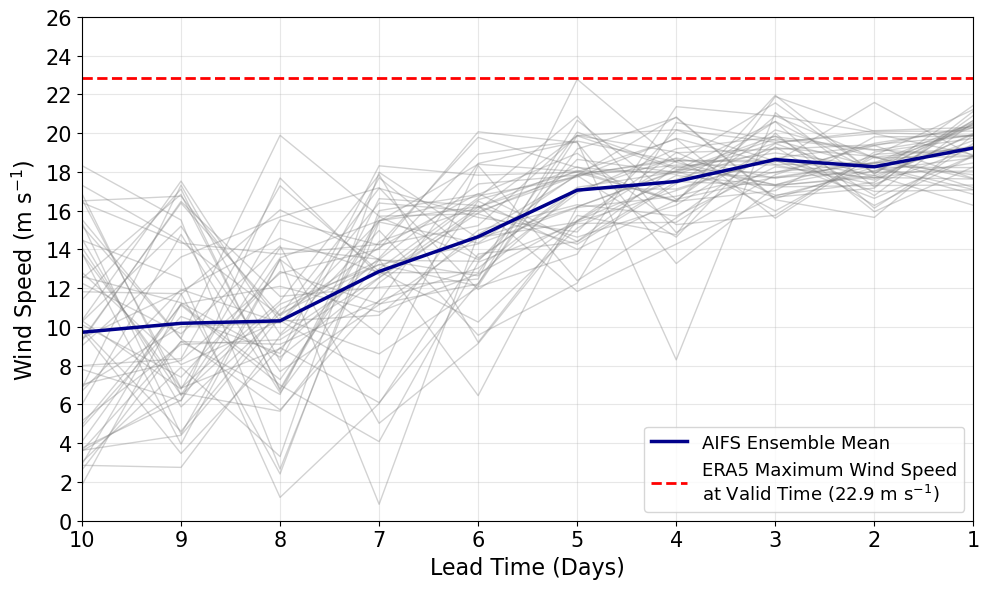

In [38]:
fig, ax = plt.subplots(figsize=(10, 6))

# Use the already selected AIFS surface wind speed
# at the ERA5 maximum location
aifs_spaghetti = ds_AIFS_sfc_sel_wind_speed

# Use actual leadtime coordinate
leadtimes = aifs_spaghetti["leadtime"].values
n_leads = len(leadtimes)

# Convert leadtime labels to days when stored as timedelta64
if np.issubdtype(leadtimes.dtype, np.timedelta64):
    leadtime_days = (leadtimes / np.timedelta64(1, "D")).astype(int)
else:
    leadtime_days = leadtimes.astype(int)

# X positions: longest lead time on the left
x_positions = np.arange(1, n_leads + 1)
xtick_labels = list(leadtime_days[::-1])

# Plot one thin grey line per ensemble member
ensemble_members = aifs_spaghetti["ensemble_members"].values

for member in ensemble_members:
    member_values = (
        aifs_spaghetti
        .sel(ensemble_members=member)
        .values[::-1]
    )

    ax.plot(
        x_positions,
        member_values,
        color="gray",
        alpha=0.35,
        linewidth=1.0
    )

# Plot ensemble mean
ensemble_mean = (
    aifs_spaghetti
    .mean(dim="ensemble_members")
    .values[::-1]
)

ax.plot(
    x_positions,
    ensemble_mean,
    color="darkblue",
    linewidth=2.5,
    label="AIFS Ensemble Mean"
)

# ERA5 reference as horizontal dashed line
ax.axhline(
    wind_speed_max_ERA5_sfc,
    color="red",
    linestyle="--",
    linewidth=2,
    label=(
        "ERA5 Maximum Wind Speed\n"
        "at Valid Time "
        f"({wind_speed_max_ERA5_sfc:.1f} m s$^{{-1}}$)"
    )
)

# Tick labels
ax.set_xticks(x_positions)
ax.set_xticklabels(xtick_labels, fontsize=15)

ax.set_xlim(
    x_positions[0],
    x_positions[-1]
)

ax.tick_params(axis="y", labelsize=15)

# Valid time
valid_time = pd.to_datetime(
    aifs_spaghetti["fc_valid_time"].values[0]
)
time_str = valid_time.strftime("%Y-%m-%d %H:%M")

ax.set_xlabel("Lead Time (Days)", fontsize=16)
ax.set_ylabel("Wind Speed (m s$^{-1}$)", fontsize=16)

# Determine readable y-axis limits
wind_all = np.concatenate([
    aifs_spaghetti.values.ravel(),
    np.array([wind_speed_max_ERA5_sfc])
])

y_low = max(
    0,
    2 * np.floor(np.nanmin(wind_all) / 2) - 2
)
y_high = (
    2 * np.ceil(np.nanmax(wind_all) / 2) + 2
)

ax.set_ylim(y_low, y_high)
ax.set_yticks(np.arange(y_low, y_high + 0.1, 2))

ax.legend(fontsize=13, loc="lower right")
ax.set_axisbelow(True)
ax.grid(alpha=0.3)

fig.tight_layout()

png_path, pdf_path = save_plot(
    fig,
    "spaghetti_plot_sfc_AIFS_ERA5_max"
)

plt.show()
plt.close(fig)

Plots saved as:
PNG: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\01_png\20260723_wind_spaghetti_plot_sfc_AIFS_ERA5_max.png
PDF: C:\Users\chris\OneDrive - Universitaet Bern\Uni\02_Geo\02_MSc\02_FS_2026\05_Seminar_in_Climatology_and_Climate_Risks\01_Case_Study\01_Code\01_Plots\01_wind\02_pdf\20260723_wind_spaghetti_plot_sfc_AIFS_ERA5_max.pdf


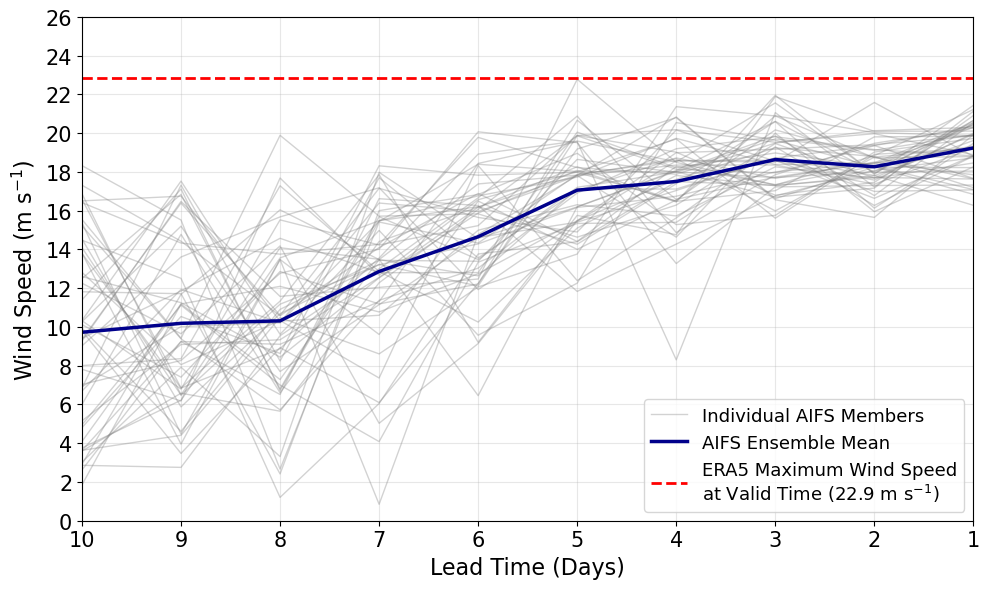

In [39]:
fig, ax = plt.subplots(figsize=(10, 6))

# Use the already selected AIFS surface wind speed
# at the ERA5 maximum location
aifs_spaghetti = ds_AIFS_sfc_sel_wind_speed

# Use actual leadtime coordinate
leadtimes = aifs_spaghetti["leadtime"].values
n_leads = len(leadtimes)

# Convert leadtime labels to days when stored as timedelta64
if np.issubdtype(leadtimes.dtype, np.timedelta64):
    leadtime_days = (leadtimes / np.timedelta64(1, "D")).astype(int)
else:
    leadtime_days = leadtimes.astype(int)

# X positions: longest lead time on the left
x_positions = np.arange(1, n_leads + 1)
xtick_labels = list(leadtime_days[::-1])

# Plot one thin grey line per ensemble member
ensemble_members = aifs_spaghetti["ensemble_members"].values

for member in ensemble_members:
    member_values = (
        aifs_spaghetti
        .sel(ensemble_members=member)
        .values[::-1]
    )

    ax.plot(
        x_positions,
        member_values,
        color="gray",
        alpha=0.35,
        linewidth=1.0
    )

# Plot ensemble mean
ensemble_mean = (
    aifs_spaghetti
    .mean(dim="ensemble_members")
    .values[::-1]
)

ax.plot(
    x_positions,
    ensemble_mean,
    color="darkblue",
    linewidth=2.5,
    label="AIFS Ensemble Mean"
)

# ERA5 reference as horizontal dashed line
ax.axhline(
    wind_speed_max_ERA5_sfc,
    color="red",
    linestyle="--",
    linewidth=2,
    label=(
        "ERA5 Maximum Wind Speed\n"
        "at Valid Time "
        f"({wind_speed_max_ERA5_sfc:.1f} m s$^{{-1}}$)"
    )
)

# Tick labels
ax.set_xticks(x_positions)
ax.set_xticklabels(xtick_labels, fontsize=15)

ax.set_xlim(
    x_positions[0],
    x_positions[-1]
)

ax.tick_params(axis="y", labelsize=15)

# Valid time
valid_time = pd.to_datetime(
    aifs_spaghetti["fc_valid_time"].values[0]
)
time_str = valid_time.strftime("%Y-%m-%d %H:%M")

ax.set_xlabel("Lead Time (Days)", fontsize=16)
ax.set_ylabel("Wind Speed (m s$^{-1}$)", fontsize=16)

# Determine readable y-axis limits
wind_all = np.concatenate([
    aifs_spaghetti.values.ravel(),
    np.array([wind_speed_max_ERA5_sfc])
])

y_low = max(
    0,
    2 * np.floor(np.nanmin(wind_all) / 2) - 2
)
y_high = (
    2 * np.ceil(np.nanmax(wind_all) / 2) + 2
)

ax.set_ylim(y_low, y_high)
ax.set_yticks(np.arange(y_low, y_high + 0.1, 2))

legend_handles = [
    Line2D(
        [0],
        [0],
        color="gray",
        linewidth=1.0,
        alpha=0.35,
        label="Individual AIFS Members"
    ),
    Line2D(
        [0],
        [0],
        color="darkblue",
        linewidth=2.5,
        label="AIFS Ensemble Mean"
    ),
    Line2D(
        [0],
        [0],
        color="red",
        linestyle="--",
        linewidth=2,
        label=(
            "ERA5 Maximum Wind Speed\n"
            "at Valid Time "
            f"({wind_speed_max_ERA5_sfc:.1f} m s$^{{-1}}$)"
        )
    )
]

ax.legend(
    handles=legend_handles,
    fontsize=13,
    loc="lower right"
)

ax.set_axisbelow(True)
ax.grid(alpha=0.3)

fig.tight_layout()

png_path, pdf_path = save_plot(
    fig,
    "spaghetti_plot_sfc_AIFS_ERA5_max"
)

plt.show()
plt.close(fig)